![Banner](../../../../Images/Banner/07_remote_sensing/09_09_banner_rs_image_classification.png)


# Crop Classification with Sentinel-1 SAR Time Series: Pixel Classifiers and Deep CNNs (VV/VH, May-October 2024)

Optical sensors need clear skies; **synthetic aperture radar (SAR)** does not.


## Overview

Sentinel-1 is a C-band (5.4 GHz, $\lambda\approx5.5$ cm) radar that images the surface day and night, through cloud, every 6 to 12 days. What it records is not colour but **backscatter**: how much of the transmitted microwave pulse returns to the antenna. Backscatter depends on the *structure* of the target (the size, orientation and water content of leaves, stems and soil) and so changes as a crop emerges, grows and senesces. A single SAR image says little about a crop, but a **time series** does.

This notebook classifies crops in the US Corn Belt (central Iowa AOI `Corn_belt/aoi.geojson`) in 2024 from five dual-polarisation (VV, VH) Sentinel-1 RTC scenes, May to October, with the 10 m USDA Cropland Data Layer (CDL) as labels, using `geolattice.rsense.sar` (speckle filtering, dB conversion) and `geolattice.rsense.classify.image_classification` (chips, pixel and deep-learning classifiers, evaluation).

> How much of the corn/soybean/other-land pattern can five Sentinel-1 dates reveal, does a convolutional network that sees *neighbourhoods* beat a pixel classifier that sees only the temporal profile, and which dates, polarisations and speckle treatment matter?

* **SAR fundamentals.** Backscatter, speckle and the equivalent number of looks (ENL), the decibel scale, the Lee and Quegan-Yu multi-temporal filters, and what VV and VH measure over crops.
* **Data.** Five 10 m gamma-naught (RTC) scenes of 2024 and the CDL on a common grid.
* **Baselines and deep learning.** A Random Forest on the 10-value temporal profile, then nine CNN, ResNet, EfficientNet, ConvNeXt, ViT and Swin architectures on $32\times32$ px, 10-channel chips, explained with their mathematics.
* **SAR-specific experiments.** Raw versus filtered input, VV versus VH, which acquisition date matters, and how early in the season a crop map can be made.
* **Evaluation.** Spatial-block splits, bootstrap metrics, a wall-to-wall map checked pixel by pixel against the CDL, and an error analysis at field boundaries.

GPU recommended; the experiments shrink automatically on a CPU.


## Core concepts

### Learning objectives

1. Explain backscatter, speckle, ENL and the dB transform, and apply `to_db`, `lee` and `multitemporal_speckle_filter`.
2. Read the temporal backscatter signature of corn, soybeans and other land cover in VV, VH and VH−VV.
3. Build a co-registered SAR time-series tensor and CDL label raster, cut chips, derive scene labels, and split spatially without leakage.
4. Fit a pixel-based Random Forest baseline and evaluate it on the same held-out blocks as the CNNs.
5. Explain the building blocks and mathematics of LeNet, VGG, ResNet, EfficientNet, ConvNeXt, ViT and Swin, and compare their size, receptive field and cost.
6. Test which SAR ingredients matter (speckle filter, polarisation, acquisition dates) with repeated seeds, and train, reload and evaluate a final model.
7. Judge the result honestly: bootstrap intervals, seed SD, pixel-level map accuracy and errors at field edges.

### Contents

1. Setup: libraries, device and data paths
2. Radar backscatter, speckle and crops: concepts and mathematics
3. Loading the 2024 Sentinel-1 time series and the CDL labels
4. Speckle filtering and the decibel scale
5. Temporal backscatter signatures of crops
6. From rasters to tensors: chips, scene labels, spatial split and class imbalance
7. Pixel-based baseline: Random Forest on the temporal profile
8. CNN architectures and the mathematics behind them
9. Data augmentation for overhead imagery
10. Loss functions: cross-entropy, weighted, focal and label smoothing
11. Training and experiments: architectures, SAR inputs, augmentation and losses
12. Final model: early stopping, checkpoint and TensorBoard
13. Inference and evaluation: chips, wall-to-wall map and field boundaries
14. Summary of the experiments
15. Interpretation, caveats and recommended recipe


### Task and evaluation design

**Data:** five Sentinel-1 IW GRD scenes processed to terrain-corrected **gamma-naught** ($\gamma^0$, linear power, 10 m, VV and VH), 21 May, 13 July, 18 August, 11 September and 17 October 2024 · CDL 2024 at 10 m (labels) · AOI `Corn_belt/aoi.geojson` (about 30 km $\times$ 29 km).

**Task.** *Scene (chip) classification*: each $32\times32$ px chip (320 m $\times$ 320 m, **10 channels** = 2 polarisations $\times$ 5 dates, in dB) receives one label, the **majority CDL class** inside the chip. A pixel baseline and a pixel-level evaluation of the wall-to-wall map against the 10 m CDL complete the picture.

**Honest evaluation.** Neighbouring chips overlap (stride 16 px) and share spatial autocorrelation. We therefore split by **256 px spatial blocks** (`group_split`) so that no block contributes to two splits, verified with `check_split_isolation`. The pixel Random Forest is trained and tested on the *same* blocks. All test blocks come from the same scene, so the numbers describe *spatial* generalisation inside the AOI and one season, not transfer to another year or region.

**Data limits to keep in mind.** The June acquisition is missing (no scene covered the AOI that month), so the series has a gap between 21 May and 13 July, which is exactly when corn and soybean canopies develop. The May scene comes from **relative orbit 165** and the other four from **orbit 63**, so its incidence angle differs. The CDL is itself a model product (about 95 % accurate for corn and soybeans), not field truth.

| Step | Functions |
|---|---|
| SAR pre-processing | `s1.lee`, `s1.multitemporal_speckle_filter`, `s1.to_db`, `s1.enl_estimate` |
| Pixel baseline | `sample_pixels`-style sampling, `train_pixel_classifier`, `predict_map` |
| Tensors, datasets, loaders | `set_seed`, `extract_chips`, `ChipDataset`, `as_loader`, `Normalizer` |
| Scene labels, imbalance, split | majority class per chip, `group_split`, `check_split_isolation`, `class_weights` |
| Architectures | `build_cnn`, `count_parameters`, `receptive_field` |
| Augmentation, losses | `OverheadAugment`, `cutmix`, `get_loss` |
| Training | `train_model`, `load_checkpoint` |
| Inference, evaluation | `predict_proba_batches`, `predict_chip_map`, `classification_report` |


## Setup: libraries, device and data paths

**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
import json, time, warnings, tempfile  # JSON, timing, warnings and temporary folders
from pathlib import Path  # file paths
warnings.filterwarnings("ignore")  # hide library warnings
# arrays, tables, labelled rasters, raster I/O and vector data
import numpy as np, pandas as pd, xarray as xr, rioxarray, geopandas as gpd
import matplotlib.pyplot as plt  # figures
from matplotlib.colors import ListedColormap  # class colours
import torch  # PyTorch: the networks
import geolattice.rsense.sar as s1  # GeoLattice SAR tools (speckle filters, dB conversion)
import geolattice.rsense.classify.image_classification as ic  # GeoLattice image-classification module

CANDIDATES = [Path("../../../../Data/08_remote_sensing/08_09_image_classification/Corn_belt"),  # the data folder, from the notebook folder or the repository root
              Path("Data/08_remote_sensing/08_09_image_classification/Corn_belt")]
DATA = next((p for p in CANDIDATES if p.is_dir()), None)  # the first candidate that exists
if DATA is None:  # neither found
    # stop with a clear message
    raise FileNotFoundError("Run Jupyter from this notebook's folder or from the GeoLattice repository root.")
S1_DIR = DATA / "Sentinel_1"  # the Sentinel-1 folder
# one scene per month, May to October 2024
S1_FOLDERS = ["2024_05_20240521_165", "2024_07_20240713_63", "2024_08_20240818_63",
              "2024_09_20240911_63", "2024_10_20241017_63"]
CDL_PATH = DATA / "CDL" / "10_m" / "CDL_2024_10m.tif"  # the 2024 CDL at 10 m
AOI_PATH = DATA / "aoi.geojson"  # the study-area polygon
# every VV/VH file and the CDL ...
for p in [S1_DIR / f / f"{pol}.tif" for f in S1_FOLDERS for pol in ("vv", "vh")] + [CDL_PATH, AOI_PATH]:
    if not p.exists():  # ... must exist
        raise FileNotFoundError(p)  # stop if one is missing

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # GPU when available
print("torch", torch.__version__, "| device:", DEVICE,  # PyTorch version and device
      "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "CPU only (reduce EPOCHS / SEEDS below)")
SEED = 42  # random seed
ic.set_seed(SEED)  # reproducible numpy and PyTorch randomness
SCALE = 1.0 if DEVICE == "cuda" else 0.4   # CPU users: shrink the experiments
# epochs and seeds of the experiments (fewer on a CPU)
EPOCHS_ARCH, EPOCHS_ABL, SEEDS = (15, 12, [0, 1, 2]) if DEVICE == "cuda" else (4, 4, [0])


torch 2.14.0+cu132 | device: cuda | NVIDIA RTX A5500 Laptop GPU


## Radar backscatter, speckle and crops: concepts and mathematics

### Backscatter and the decibel scale
A SAR image stores, for each pixel, the received **power** $I$. After radiometric calibration and terrain correction (the *RTC* products used here) the pixel holds the **gamma-naught** backscatter coefficient,

$$\gamma^0=\frac{\sigma^0}{\cos\theta_i},\qquad \sigma^0=\frac{\langle |S|^2\rangle}{A_{\text{ground}}}\ \ (\text{linear power per unit area}),$$

where $\theta_i$ is the local incidence angle. Dividing by $\cos\theta_i$ removes most of the incidence-angle dependence of vegetated surfaces, so values from different parts of the swath, and from different orbits, are comparable. Backscatter spans orders of magnitude (here $10^{-3}$ to $0.5$), so it is analysed on the logarithmic **decibel** scale,

$$\gamma^0_{\mathrm{dB}}=10\log_{10}\gamma^0 ,\qquad \gamma^0=10^{\gamma^0_{\mathrm{dB}}/10}.$$

Typical values: smooth water $<-20$ dB, bare soil and crop canopies $-25$ to $-10$ dB in VH and $-18$ to $-5$ dB in VV, buildings and rough surfaces above $-5$ dB.

### Speckle
The pixel is the coherent sum of echoes from many scatterers inside the resolution cell. Their phases interfere randomly, so even a perfectly homogeneous field looks grainy. This **speckle** is multiplicative,

$$I=\sigma\,n,\qquad n\sim\Gamma\!\Big(L,\tfrac1L\Big),\quad \mathbb E[n]=1,\quad \operatorname{Var}[n]=\frac1L,$$

where $\sigma$ is the true backscatter and $L$ the **number of looks** (independent averages). The **equivalent number of looks** of a homogeneous area is estimated as

$$\mathrm{ENL}=\frac{\mathbb E[I]^2}{\operatorname{Var}[I]}=\frac{1}{\mathrm{CV}^2},\qquad \mathrm{CV}=\frac{\sigma_I}{\mu_I}.$$

For $L$ independent looks the coefficient of variation is $1/\sqrt{L}$, so a single-look pixel has a CV of 1 and an ENL of 1, whereas Sentinel-1 GRD at 10 m has an ENL of roughly 4 to 5 (the product is multi-looked). Speckle also **biases the dB mean**: the expectation of the logarithm of a gamma variable is

$$\mathbb E\big[10\log_{10}I\big]=10\log_{10}\sigma+\frac{10}{\ln10}\big[\psi(L)-\ln L\big],$$

with $\psi$ the digamma function (about $-1.3$ dB for $L=4.4$). Averages should therefore be taken in the **linear** domain and converted to dB afterwards, which is what the filters below do.

### Speckle filters
The **Lee filter** (1980) estimates the noise-free value as a weighted mix of the local mean $\bar z$ and the centre pixel $z$,

$$\hat x=\bar z+b\,(z-\bar z),\qquad b=\frac{\sigma_x^2}{\sigma_z^2},\qquad \sigma_x^2=\frac{\sigma_z^2-\bar z^2\sigma_n^2}{1+\sigma_n^2},\quad \sigma_n^2=\frac1{\mathrm{ENL}} .$$

In a homogeneous window $\sigma_z^2\approx\bar z^2\sigma_n^2$, so $b\to0$ and the output is the local mean; at an edge the local variance is large, $b\to1$ and the pixel is kept. `s1.lee(img, size, enl)` implements it for one date.

The **Quegan-Yu multi-temporal filter** (2001) uses all $N$ co-registered dates. Each date keeps its own local mean $E[I_k]$ (any spatial filter $E[\cdot]$) while the speckle is averaged across dates,

$$J_k=\frac{E[I_k]}{N}\sum_{i=1}^{N}\frac{I_i}{E[I_i]} .$$

The ratio $I_i/E[I_i]$ is, to first order, pure speckle, which is independent between dates (the acquisitions are 4 to 8 weeks apart), so it is averaged over $N$ dates; the temporal signal sits in $E[I_k]$ and is left untouched. `s1.multitemporal_speckle_filter` reduces speckle by up to $\sqrt N$ without the spatial blurring of a single-date filter of the same strength.

### What VV and VH see over crops
* **VV** (vertical transmit, vertical receive) is dominated by *surface* scattering from soil and by attenuated returns through the canopy; it responds to soil moisture and roughness, and to vertical stalks.
* **VH** (cross-polarised) arises mainly from *volume* scattering inside the canopy, where leaves and stems depolarise the wave. It rises with biomass and canopy water content and is less sensitive to the soil.
* Derived quantities: the **cross-polarisation ratio** $\mathrm{CR}=\gamma^0_{VH}/\gamma^0_{VV}$ (in dB simply $\mathrm{VH}_{\mathrm{dB}}-\mathrm{VV}_{\mathrm{dB}}$) and the radar vegetation index $\mathrm{RVI}=4\gamma^0_{VH}/(\gamma^0_{VV}+\gamma^0_{VH})$.
* **Corn versus soybeans.** Corn grows to 2 to 3 m with thick stalks and large leaves and holds much more biomass than soybeans (about 1 m). Mid-season it is therefore expected to have higher volume scattering (VH) than soybeans, and the two crops differ in their rate of change during emergence and senescence. How large these differences are in practice, and whether five dates are enough to separate them, is what the experiments measure.


## Loading the 2024 Sentinel-1 time series and the CDL labels

### Acquisition inventory
The `inventory.csv` produced by the download script lists, for each month, the scene chosen (the scene with the best AOI coverage, from the dominant relative orbit when possible). In 2024 June has no acquisition covering the AOI, and the May scene had to come from another orbit.


In [2]:
inv = pd.read_csv(S1_DIR / "inventory.csv")  # the download inventory
# the five scenes used, in time order
inv24 = inv[inv["folder"].isin(S1_FOLDERS)].set_index("folder").loc[S1_FOLDERS]
# date, orbit, platform and AOI coverage
print(inv24[["date", "relative_orbit", "orbit_state", "platform", "aoi_footprint_cover"]].to_string())
# months of 2024 without a usable scene
print("\nmonths 2024 without an acquisition:", inv[(inv.year == 2024) & (inv.status != "downloaded")]["month"].tolist())
DATES = pd.to_datetime(inv24["date"].values)  # acquisition dates
DLAB = [d.strftime("%d %b") for d in DATES]  # short date labels
T = len(DATES)  # number of dates

                            date  relative_orbit orbit_state     platform  aoi_footprint_cover
folder                                                                                        
2024_05_20240521_165  2024-05-21           165.0   ascending  SENTINEL-1A               0.9971
2024_07_20240713_63   2024-07-13            63.0   ascending  SENTINEL-1A               1.0000
2024_08_20240818_63   2024-08-18            63.0   ascending  SENTINEL-1A               1.0000
2024_09_20240911_63   2024-09-11            63.0   ascending  SENTINEL-1A               1.0000
2024_10_20241017_63   2024-10-17            63.0   ascending  SENTINEL-1A               1.0000

months 2024 without an acquisition: [6]


### The SAR stack: linear power on a common 10 m grid
Each scene is read as float32; the nodata value $-32768$ (and non-positive values, which cannot be converted to dB) become `NaN`. All five scenes share one UTM zone 15N grid, which we verify. The AOI polygon is compared with the raster footprint.


In [3]:
def read_pol(folder, pol):  # one polarisation of one scene as linear power
    # read it as float32
    a = rioxarray.open_rasterio(S1_DIR / folder / f"{pol}.tif").squeeze(drop=True).astype("float32")
    return a.where((a != -32768) & (a > 0))  # -32768 and non-positive values are no data

lin = {}  # polarisation -> (time, y, x) stack
for pol in ("vv", "vh"):  # VV and VH
    layers = [read_pol(f, pol) for f in S1_FOLDERS]  # the five dates
    for l in layers[1:]:  # every date ...
        # ... must be on exactly the same grid
        assert l.shape == layers[0].shape and np.array_equal(l.x.values, layers[0].x.values) and np.array_equal(l.y.values, layers[0].y.values)
    lin[pol] = xr.concat(layers, dim="time").assign_coords(time=DATES.values)  # stacked along time
ref = lin["vv"].isel(time=0).drop_vars("time")  # the grid as a reference raster
aoi = gpd.read_file(AOI_PATH).to_crs(ref.rio.crs)  # the AOI in the same CRS
H, W = ref.shape  # grid size
# stack size, CRS and pixel size
print(f"stack: {T} dates x 2 pol x {H} x {W} px | CRS {ref.rio.crs} | pixel {abs(float(ref.rio.resolution()[0])):.0f} m | "
      f"{H * W / 1e6:.1f} M pixels per layer")
# AOI area, raster footprint and complete-data share
print(f"AOI polygon area {aoi.area.sum() / 1e6:,.0f} km2 | raster footprint {H * W * 100 / 1e6:,.0f} km2 | "
      f"share of pixels with data (all dates, both pol): {np.isfinite(lin['vv']).all('time').mean().item():.4f}")
print("linear power percentiles (1 / 50 / 99 %), per date:")  # header
# 1st, 50th and 99th percentiles per date and polarisation
print(pd.DataFrame({pol: [np.nanpercentile(lin[pol].isel(time=t).values[::7, ::7], [1, 50, 99]).round(4).tolist() for t in range(T)]
                    for pol in lin}, index=DLAB).to_string())

stack: 5 dates x 2 pol x 2911 x 3032 px | CRS EPSG:32615 | pixel 10 m | 8.8 M pixels per layer
AOI polygon area 863 km2 | raster footprint 883 km2 | share of pixels with data (all dates, both pol): 1.0000
linear power percentiles (1 / 50 / 99 %), per date:
                              vv                        vh
21 May  [0.0167, 0.0606, 0.2175]  [0.0027, 0.0081, 0.0459]
13 Jul  [0.0269, 0.1021, 0.2912]  [0.0059, 0.0242, 0.0677]
18 Aug   [0.036, 0.1374, 0.4078]  [0.0087, 0.0304, 0.0804]
11 Sep  [0.0275, 0.1158, 0.4104]  [0.0066, 0.0274, 0.1045]
17 Oct    [0.01, 0.0438, 0.1982]  [0.0013, 0.0069, 0.0391]


### CDL labels recoded to six land-cover classes
The 10 m CDL raster (Albers, EPSG:5070) is reprojected to the Sentinel-1 grid with **nearest neighbour** (class codes must not be interpolated). The CDL's detailed crop legend is merged into six classes; corn and soybeans make up about 90 % of the AOI, so the problem is strongly imbalanced.


In [4]:
# CDL on the 10 m grid (nearest neighbour)
cdl = rioxarray.open_rasterio(CDL_PATH).squeeze(drop=True).rio.reproject_match(ref, resampling=0)
code_map = {1: 0, 5: 1, 176: 2, 121: 3, 122: 3, 123: 3, 124: 3, 190: 4, 195: 4}  # CDL code -> class id
CLASSES = ["Corn", "Soybeans", "Grass/pasture", "Developed", "Wetland/forest", "Other"]  # the six classes
COLORS = ["#e6c229", "#2a9d3c", "#b9e08b", "#d7301f", "#1f5fbf", "#7f7f7f"]
K = len(CLASSES)  # number of classes
cmap = ListedColormap(COLORS)  # their colour map
raw = cdl.values.astype(int)  # CDL codes as integers
lab = np.full(raw.shape, 5, "int16")  # everything else is "Other" (5)
for k, v in code_map.items():  # the mapped codes ...
    lab[raw == k] = v  # ... get their class
lab[raw == 0] = -1  # no data
share = pd.Series(lab[lab >= 0]).value_counts(normalize=True).sort_index()  # share of each class
# as a small table
print(pd.DataFrame({"class": CLASSES, "pixel share": share.reindex(range(K)).round(4).values}).to_string(index=False))
# the largest CDL codes inside "Other"
other = pd.Series(raw[lab == 5]).value_counts(normalize=True).head(5).round(3)
# report them
print("largest CDL codes inside 'Other':", other.to_dict(), "(36 = alfalfa, 28 = oats, 141 = deciduous forest)")

         class  pixel share
          Corn       0.4879
      Soybeans       0.4085
 Grass/pasture       0.0482
     Developed       0.0372
Wetland/forest       0.0087
         Other       0.0096
largest CDL codes inside 'Other': {28: 0.24, 141: 0.229, 36: 0.187, 111: 0.162, 131: 0.086} (36 = alfalfa, 28 = oats, 141 = deciduous forest)


## Speckle filtering and the decibel scale

We build three versions of the same 10-channel dB image and compare them in the experiments of the *Training and experiments: architectures, SAR inputs, augmentation and losses* section:

| Version | Processing |
|---|---|
| `raw` | no filter, linear power $\to$ dB |
| `lee` | single-date Lee filter, $5\times5$, ENL 4.4, per date and polarisation |
| `mt` | **multi-temporal Quegan-Yu** filter with Lee $5\times5$ as the spatial filter, applied across the five dates, per polarisation |

Filtering is done in **linear power**, and the result is converted to dB afterwards (see *Speckle*). The ENL is measured over a $40\times40$ px block that the CDL labels as a single class (soybeans or corn) and whose reflectance looks homogeneous: it is an *indicative* number, because a real field still has texture and soil variation, which lowers the estimate.


In [5]:
ENL0 = 4.4  # assumed number of looks of the RTC product
t0 = time.time()  # start the timer
# multi-temporal, single-date Lee and unfiltered stacks
flt = {"mt": {p: s1.multitemporal_speckle_filter(lin[p], spatial="lee", size=5, enl=ENL0) for p in lin},
       "lee": {p: xr.concat([s1.lee(lin[p].isel(time=t).drop_vars("time"), size=5, enl=ENL0) for t in range(T)], dim="time")
                   .assign_coords(time=DATES.values) for p in lin},
       "raw": lin}
print(f"filters computed in {time.time() - t0:.0f} s")  # time taken

BAND_NAMES = [f"{pol.upper()} {d}" for pol in ("vv", "vh") for d in DLAB]  # band names: polarisation and date
def to_bands(d):  # a filtered stack -> 10 bands in dB
    # every date of both polarisations, in dB
    parts = [s1.to_db(d[pol].isel(time=t)).drop_vars("time") for pol in ("vv", "vh") for t in range(T)]
    # as one (band, y, x) array
    return xr.concat(parts, dim="band").assign_coords(band=BAND_NAMES).astype("float32")
IMG = {k: to_bands(v) for k, v in flt.items()}  # all three versions
print({k: (tuple(v.shape), f"{v.nbytes / 1e9:.2f} GB") for k, v in IMG.items()})  # their shapes and memory

from scipy.ndimage import uniform_filter  # moving-window mean
for cls_id, nm in [(1, "Soybeans"), (0, "Corn")]:  # a pure soybean block and a pure corn block
    # pixels whose 40 x 40 neighbourhood is all one class
    pure = uniform_filter((lab == cls_id).astype("float32"), 40, mode="constant") > 0.999
    cand = np.argwhere(pure)  # their positions
    if len(cand):  # found one
        # the middle candidate; top-left corner of the block
        r0, c0 = (int(v) for v in cand[len(cand) // 2]); r0 -= 20; c0 -= 20
        blk = (slice(r0, r0 + 40), slice(c0, c0 + 40))  # the 40 x 40 window
        print(f"\nENL over a pure {nm} block (rows {r0}:{r0 + 40}, cols {c0}:{c0 + 40}):")  # header
        rows = {}  # one row per polarisation
        for pol in ("vv", "vh"):  # each polarisation
            # equivalent number of looks of each version on 18 August
            rows[pol.upper()] = {k: s1.enl_estimate(flt[k][pol].isel(time=2).values[blk]) for k in ("raw", "lee", "mt")}
        # as a table
        print(pd.DataFrame(rows).round(1).T.rename(columns={"raw": "raw", "lee": "single-date Lee", "mt": "multi-temporal Lee"}).to_string())
        if nm == "Soybeans": BLK_HOM = blk  # keep the soybean block for later

filters computed in 9 s


{'mt': ((10, 2911, 3032), '0.35 GB'), 'lee': ((10, 2911, 3032), '0.35 GB'), 'raw': ((10, 2911, 3032), '0.35 GB')}

ENL over a pure Soybeans block (rows 1476:1516, cols 353:393):
    raw  single-date Lee  multi-temporal Lee
VV  6.6             31.7                18.0
VH  6.7             26.7                16.0

ENL over a pure Corn block (rows 1346:1386, cols 390:430):
    raw  single-date Lee  multi-temporal Lee
VV  5.6             21.0                14.7
VH  7.0             33.4                17.9


**Reading the ENL table.** An ENL near 4 to 6 for the raw 10 m data confirms the speckle model: single pixels carry a noise standard deviation of about $1/\sqrt{\mathrm{ENL}}\approx45$ % of their mean. Both filters raise the ENL. ENL measures noise reduction only; it does not tell how well edges and small fields are kept. The zoom below shows what the filters do to the image, in dB.


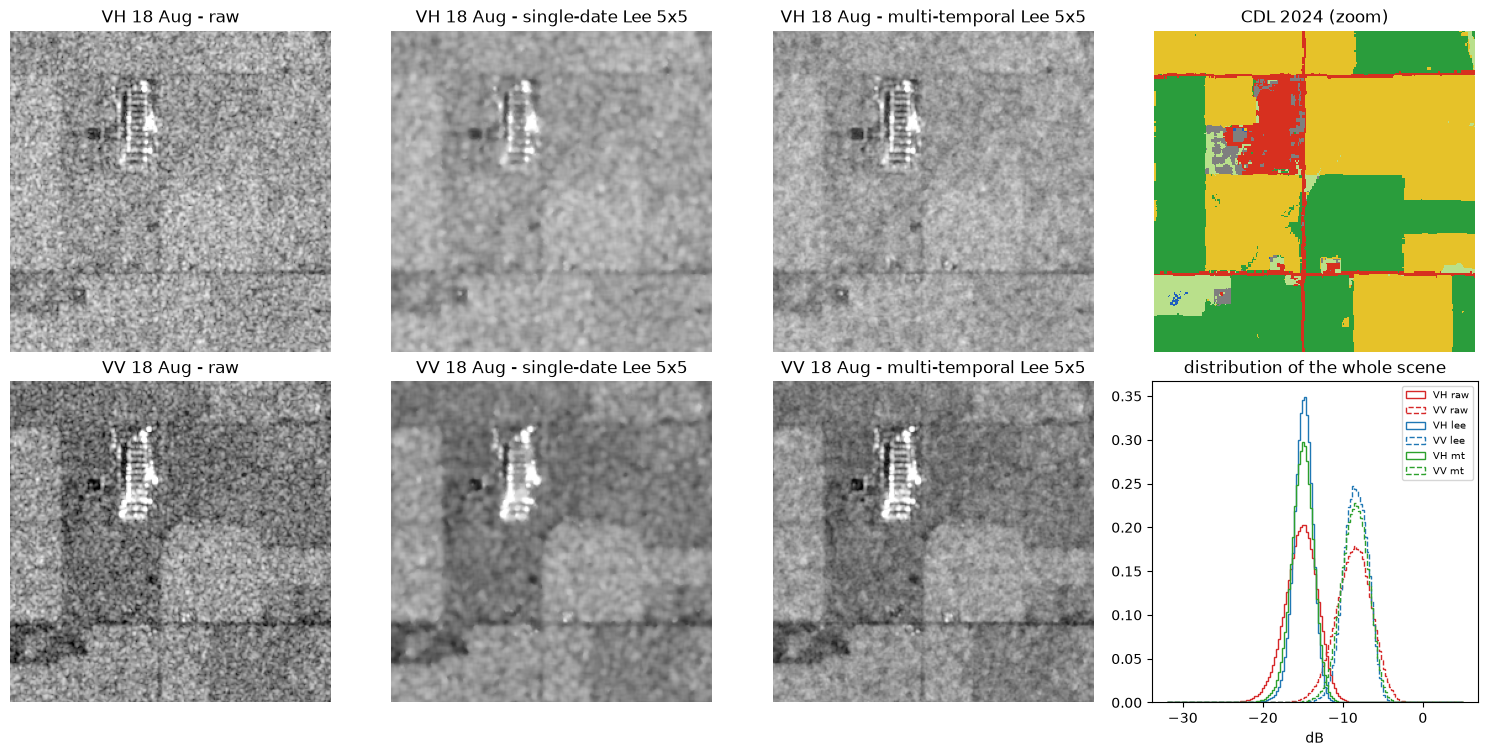

In [6]:
r0, c0 = 1100, 1300  # corner of the zoom window
zoom = (slice(r0, r0 + 260), slice(c0, c0 + 260))  # a 260 x 260 pixel zoom
t_show = 2                       # 18 Aug
fig, ax = plt.subplots(2, 4, figsize=(15, 7.6))  # two rows of four panels
# the three versions
for j, (k, ttl) in enumerate([("raw", "raw"), ("lee", "single-date Lee 5x5"), ("mt", "multi-temporal Lee 5x5")]):
    # VH zoom
    ax[0, j].imshow(IMG[k].sel(band=f"VH {DLAB[t_show]}").values[zoom], cmap="gray", vmin=-27, vmax=-8)
    ax[0, j].set_title(f"VH {DLAB[t_show]} - {ttl}")  # title
    # VV zoom
    ax[1, j].imshow(IMG[k].sel(band=f"VV {DLAB[t_show]}").values[zoom], cmap="gray", vmin=-18, vmax=0)
    ax[1, j].set_title(f"VV {DLAB[t_show]} - {ttl}")  # title
# CDL of the zoom
ax[0, 3].imshow(np.where(lab < 0, np.nan, lab)[zoom], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[0, 3].set_title("CDL 2024 (zoom)")
bins = np.linspace(-32, 5, 150)  # histogram bins in dB
for k, col in [("raw", "tab:red"), ("lee", "tab:blue"), ("mt", "tab:green")]:  # each version
    # VH histogram of the whole scene
    ax[1, 3].hist(IMG[k].sel(band=f"VH {DLAB[t_show]}").values[::5, ::5].ravel(), bins=bins, histtype="step", color=col, label=f"VH {k}", density=True)
    # VV histogram
    ax[1, 3].hist(IMG[k].sel(band=f"VV {DLAB[t_show]}").values[::5, ::5].ravel(), bins=bins, histtype="step", color=col, ls="--", label=f"VV {k}", density=True)
# labels and legend
ax[1, 3].set_xlabel("dB"); ax[1, 3].set_title("distribution of the whole scene"); ax[1, 3].legend(fontsize=7)
for a in ax.flat[:7]: a.axis("off")  # no axes on the image panels
plt.tight_layout(); plt.show()  # arrange and draw

## Temporal backscatter signatures of crops

Before any classifier, we look at what separates the classes. For 400,000 random pixels of the multi-temporal-filtered stack we plot the **median and inter-quartile range** (IQR) of VV, VH and VH−VV per class and date. The false-colour composite assigns three dates of VH to the three colour channels; a pixel is coloured by *when* it is bright: crops that grow late look different from permanent cover.


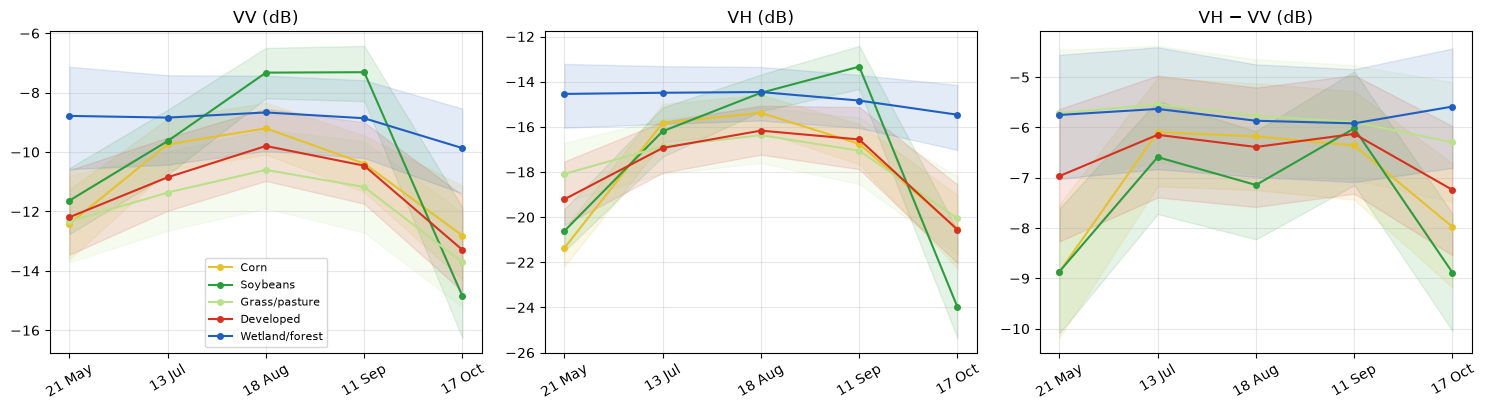

Corn versus soybeans, per band (median difference relative to the pooled SD):
  date pol  corn − soy (dB)  pooled SD (dB)  separation (d')
21 May  VV            -0.78            1.69            -0.46
13 Jul  VV            -0.11            1.51            -0.07
18 Aug  VV            -1.87            1.32            -1.42
11 Sep  VV            -3.08            1.48            -2.08
17 Oct  VV             2.04            2.46             0.83
21 May  VH            -0.76            1.51            -0.50
13 Jul  VH             0.37            1.56             0.24
18 Aug  VH            -0.89            1.25            -0.71
11 Sep  VH            -3.42            1.48            -2.31
17 Oct  VH             3.47            2.65             1.31


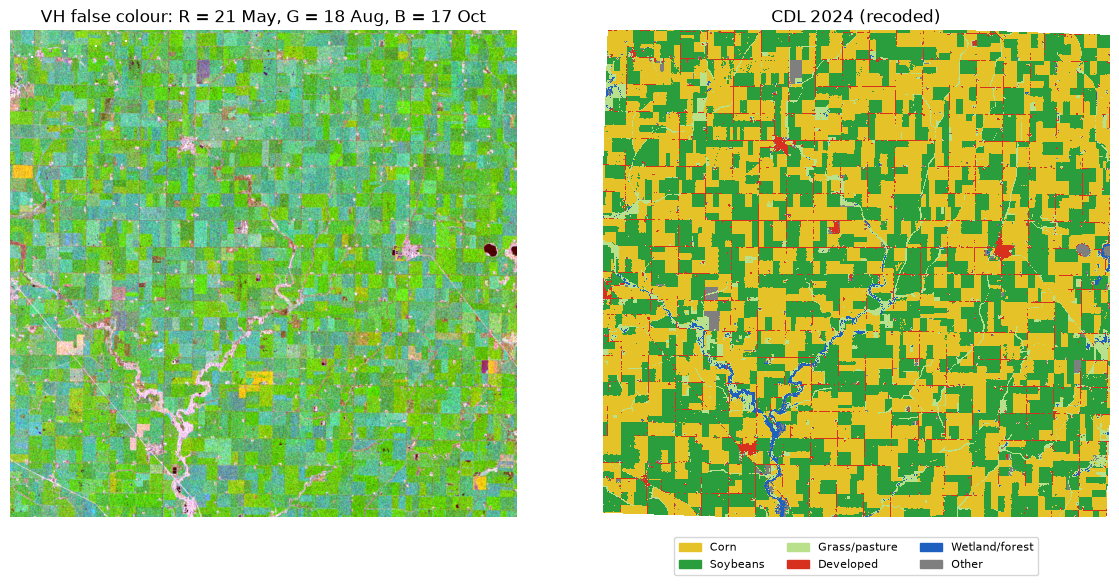

In [7]:
rng = np.random.default_rng(0)  # random generator
mt_np = IMG["mt"].values                                   # (10, H, W)
valid_px = np.isfinite(mt_np).all(0) & (lab >= 0)  # pixels with all bands and a label
idx = rng.choice(np.flatnonzero(valid_px.ravel()), 400_000, replace=False)  # 400,000 random pixels
feat = mt_np.reshape(10, -1)[:, idx].T                     # (n, 10)
labs = lab.ravel()[idx]  # their labels
vv, vh = feat[:, :T], feat[:, T:]  # VV and VH columns

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))  # three panels
x = np.arange(T)  # date positions
for k in range(K - 1):  # each class except "Other"
    # VV, VH and their difference
    for a, v, ttl in [(ax[0], vv, "VV (dB)"), (ax[1], vh, "VH (dB)"), (ax[2], vh - vv, "VH − VV (dB)")]:
        q = np.percentile(v[labs == k], [25, 50, 75], axis=0)  # quartiles over the pixels of the class
        # median line and interquartile band
        a.plot(x, q[1], "-o", color=COLORS[k], label=CLASSES[k], ms=4); a.fill_between(x, q[0], q[2], color=COLORS[k], alpha=0.12)
        a.set_title(ttl)  # title
for a in ax: a.set_xticks(x); a.set_xticklabels(DLAB, rotation=30); a.grid(alpha=0.3)  # date labels and grid
ax[0].legend(fontsize=8)  # legend
plt.tight_layout(); plt.show()  # arrange and draw

d = pd.DataFrame({"date": DLAB * 2, "pol": ["VV"] * T + ["VH"] * T,  # corn against soybeans, band by band
                  "corn − soy (dB)": [np.median(feat[labs == 0, j]) - np.median(feat[labs == 1, j]) for j in range(2 * T)],
                  "pooled SD (dB)": [np.sqrt((feat[labs == 0, j].var() + feat[labs == 1, j].var()) / 2) for j in range(2 * T)]})
# separation in pooled standard deviations
d["separation (d')"] = (d["corn − soy (dB)"] / d["pooled SD (dB)"]).round(2)
print("Corn versus soybeans, per band (median difference relative to the pooled SD):")  # header
print(d.round(2).to_string(index=False))  # the table

# VH of three dates as RGB
rgbimg = np.stack([IMG["mt"].sel(band=f"VH {DLAB[i]}").values for i in (0, 2, 4)], -1)
# stretch each date to 0-1
rgbimg = np.clip((rgbimg - np.array([-26, -24, -26])) / np.array([12, 12, 12]), 0, 1)
fig, ax = plt.subplots(1, 2, figsize=(12, 5.6))  # two panels
# the multi-date composite
ax[0].imshow(rgbimg); ax[0].set_title(f"VH false colour: R = {DLAB[0]}, G = {DLAB[2]}, B = {DLAB[4]}")
# the CDL
ax[1].imshow(np.where(lab < 0, np.nan, lab), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[1].set_title("CDL 2024 (recoded)")
for a in ax: a.axis("off")  # no axes
# class legend
ax[1].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.13))
plt.tight_layout(); plt.show()  # arrange and draw

**What the signatures say.** The separation $d'$ (median difference divided by the pooled standard deviation of the two classes) tells how many standard deviations apart the two main crops are *at the level of one pixel*. A value of 1 or more is a visible shift, but the distributions still overlap: a pixel-level classifier on one date would make many errors, which is why the next sections use all dates, then neighbourhoods. Developed land and forest/wetland stand out through high, almost seasonless backscatter (strong scatterers) and are expected to be easy.


## From rasters to tensors: chips, scene labels, spatial split and class imbalance

### Cutting 32 × 32 px image chips with `extract_chips`
`extract_chips(image, samples, size=, max_nan_fraction=)` cuts $\text{size}\times\text{size}$ chips centred on map coordinates. We lay a regular grid of chip centres (stride 16 px, so chips overlap by half) over $11\times11$ blocks of $256$ px, tag each chip with its block id, and cut the **multi-temporal-filtered** stack. The raw and single-date-filtered versions are cut at the *same* positions by array slicing (checked against `extract_chips`), so the experiments in the *Training and experiments: architectures, SAR inputs, augmentation and losses* section differ only in the input processing.


In [8]:
SIZE, STRIDE, BLOCK = 32, 16, 256  # 32 px chips, 16 px stride, 256 px blocks
nb = min(H, W) // BLOCK                                    # 11 x 11 blocks
xs, ys = IMG["mt"].x.values, IMG["mt"].y.values  # pixel-centre coordinates
pts, bid, rc = [], [], []  # chip centres, block ids and positions
for bi in range(nb):  # every block row ...
    for bj in range(nb):  # ... and column
        for r in range(bi * BLOCK, (bi + 1) * BLOCK - SIZE + 1, STRIDE):  # chip rows in the block
            for c in range(bj * BLOCK, (bj + 1) * BLOCK - SIZE + 1, STRIDE):  # chip columns in the block
                # centre, block id and position of the chip
                pts.append((xs[c + SIZE // 2], ys[r + SIZE // 2])); bid.append(bi * nb + bj); rc.append((r, c))
pts, bid, rc = np.array(pts), np.array(bid), np.array(rc)  # as arrays

t0 = time.time()  # start the timer
# chips of the filtered stack, dropping any with a missing pixel
Xall, _, xy = ic.extract_chips(IMG["mt"], pts, size=SIZE, max_nan_fraction=0.0)
# candidate centre -> index
cand = {(round(float(a), 3), round(float(b), 3)): i for i, (a, b) in enumerate(pts)}
# index of each kept chip
keep = np.array([cand[(round(float(a), 3), round(float(b), 3))] for a, b in np.asarray(xy)[:, :2]])
bid, rc = bid[keep], rc[keep]  # their block ids and positions

def cut(arr):                                              # same chips from any (C, H, W) array, by slicing
    out = np.empty((len(rc), arr.shape[0], SIZE, SIZE), "float32")  # empty chip array
    for i, (r, c) in enumerate(rc):  # every kept chip ...
        out[i] = arr[:, r:r + SIZE, c:c + SIZE]  # ... sliced at its position
    return out  # the chips
# the same chips for all three versions
XV = {"mt": Xall, "raw": cut(IMG["raw"].values), "lee": cut(IMG["lee"].values)}
# slicing gives exactly the extracted chips
print("slicing reproduces extract_chips:", bool(np.allclose(cut(IMG["mt"].values[:, :, :])[:50], Xall[:50], equal_nan=True)))
lab_da = IMG["mt"].isel(band=[0]).copy(data=lab[None].astype("float32"))  # the label map as a one-band raster
Mall, _, _ = ic.extract_chips(lab_da, pts, size=SIZE, max_nan_fraction=1.0)  # label chips at the same centres
Mall = Mall[keep, 0].astype(int)  # kept label chips as integers
# counts, time and memory
print(f"candidate chips {len(pts):,} -> clean chips {len(Xall):,} ({time.time() - t0:.1f} s) | chip tensor {Xall.shape} float32 = {Xall.nbytes / 1e9:.2f} GB "
      f"| three input versions | mask chips {Mall.shape}")

slicing reproduces extract_chips: True


candidate chips 27,225 -> clean chips 27,211 (1.6 s) | chip tensor (27211, 10, 32, 32) float32 = 1.11 GB | three input versions | mask chips (27211, 32, 32)


### Scene labels from masks
The label of a chip is the **majority class** of its mask chip,

$$y_i=\arg\max_{k}\;n_{ik},\qquad n_{ik}=\#\{\text{pixels of chip }i\text{ with class }k\},\qquad p_i=\frac{\max_k n_{ik}}{\sum_k n_{ik}}\;(\text{purity}).$$

Mixed chips (low purity $p_i$) are inherently ambiguous: a chip that is 40 % corn and 40 % soybeans cannot be labelled reliably from backscatter alone. We keep chips with $p_i\ge 0.6$ and with less than 20 % background pixels, and report how much this matters.


chips kept: 22,193 of 27,211 (81.6%) | median purity 0.93


         class  chips  share
          Corn  12075 0.5441
      Soybeans   9638 0.4343
 Grass/pasture    309 0.0139
     Developed     84 0.0038
Wetland/forest     21 0.0009
         Other     66 0.0030


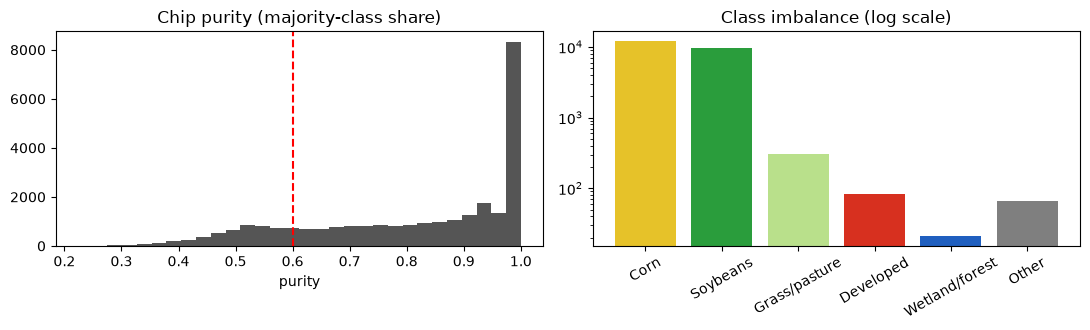

In [9]:
valid = (Mall >= 0)  # labelled pixels of every chip
counts = np.stack([(Mall == k).sum((1, 2)) for k in range(K)], 1)  # pixels of each class per chip
y_all = counts.argmax(1)  # majority class
purity = counts.max(1) / np.maximum(valid.sum((1, 2)), 1)  # its share
ok = (valid.mean((1, 2)) >= 0.8) & (purity >= 0.6)  # chips at least 80 % labelled and 60 % pure
# how many are kept
print(f"chips kept: {ok.sum():,} of {len(ok):,} ({ok.mean():.1%}) | median purity {np.median(purity[ok]):.2f}")
XV = {k: v[ok] for k, v in XV.items()}  # keep them in all three versions
X = XV["mt"]  # the multi-temporal version is the default
y, groups, chip_rc = y_all[ok], bid[ok], rc[ok]  # labels, block ids and positions
# chips per class
print(pd.DataFrame({"class": CLASSES, "chips": np.bincount(y, minlength=K), "share": (np.bincount(y, minlength=K) / len(y)).round(4)}).to_string(index=False))

fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))  # two panels
ax[0].hist(purity, bins=30, color="#555"); ax[0].axvline(0.6, color="r", ls="--"); ax[0].set_title("Chip purity (majority-class share)"); ax[0].set_xlabel("purity")
# chips per class on a log scale
ax[1].bar(CLASSES, np.bincount(y, minlength=K), color=COLORS); ax[1].set_yscale("log"); ax[1].set_title("Class imbalance (log scale)"); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()  # arrange and draw

### Spatial-block split and training-only normalisation
`group_split(groups, test_size=, val_size=)` assigns *whole blocks* to train/validation/test. `check_split_isolation` raises if any block appears in two splits. Neighbouring blocks still touch, so a small leakage along block edges remains; this is why the *Training and experiments: architectures, SAR inputs, augmentation and losses* section reports the SD over seeds and why the final numbers should be read as in-scene spatial generalisation. The `Normalizer` is fitted on **training chips only**: it z-scores each of the 10 channels, which also absorbs the constant offset between the May (orbit 165) and later (orbit 63) scenes.


train 13,339 | val 4,454 | test 4,400 chips (73/24/24 blocks) - isolation check passed
                train   val  test
Corn             7017  2518  2540
Soybeans         5938  1872  1828
Grass/pasture     251    27    31
Developed          64    20     0
Wetland/forest     19     1     1
Other              50    16     0


batch: {'image': ((128, 10, 32, 32), 'torch.float32'), 'label': ((128,), 'torch.int64')} | train mean/std per band after z-score: -0.042 0.949


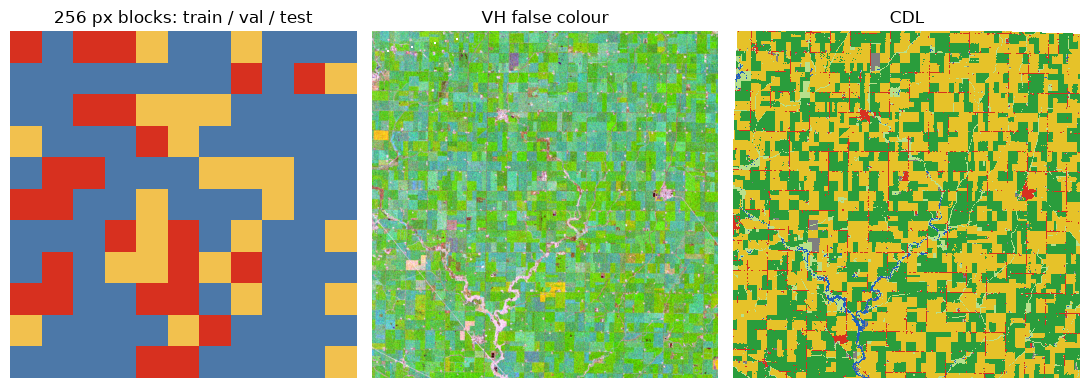

In [10]:
sp = ic.group_split(groups, test_size=0.2, val_size=0.2, seed=SEED)  # 60 / 20 / 20 split by whole blocks
tr, va, te = sp.train, sp.val, sp.test  # the three index sets
# no block in two splits
ic.check_split_isolation(train=np.unique(groups[tr]), val=np.unique(groups[va]), test=np.unique(groups[te]))
print(f"train {len(tr):,} | val {len(va):,} | test {len(te):,} chips "  # split sizes and block counts
      f"({len(np.unique(groups[tr]))}/{len(np.unique(groups[va]))}/{len(np.unique(groups[te]))} blocks) - isolation check passed")
# chips per class and split
print(pd.DataFrame({s: np.bincount(y[i], minlength=K) for s, i in [("train", tr), ("val", va), ("test", te)]}, index=CLASSES))

norm = ic.Normalizer("zscore").fit(X[tr], band_axis=1)  # per-band z-score from the training chips only
# chip dataset of indices idx
mk = lambda idx, tf=None: ic.ChipDataset(X[idx], y[idx], normalizer=norm, transform=tf)
ds_tr, ds_va, ds_te = mk(tr), mk(va), mk(te)  # the three datasets
ld_tr = ic.as_loader(ds_tr, 128, shuffle=True, seed=SEED)  # shuffled training batches
# validation and test batches
ld_va, ld_te = ic.as_loader(ds_va, 256, shuffle=False), ic.as_loader(ds_te, 256, shuffle=False)
b = next(iter(ld_tr))  # one training batch
print("batch:", {k: (tuple(v.shape), str(v.dtype)) for k, v in b.items()},  # its tensors and scaled statistics
      "| train mean/std per band after z-score:", round(float(b["image"].mean()), 3), round(float(b["image"].std()), 3))

fig, ax = plt.subplots(1, 3, figsize=(11, 4))  # three panels
bsplit = np.zeros(nb * nb)  # split of every block
# train 0, validation 1, test 2
bsplit[np.unique(groups[tr])] = 0; bsplit[np.unique(groups[va])] = 1; bsplit[np.unique(groups[te])] = 2
missing = np.setdiff1d(np.arange(nb * nb), np.unique(groups)); bsplit[missing] = np.nan  # blocks without chips
ax[0].imshow(bsplit.reshape(nb, nb), cmap=ListedColormap(["#4c78a8", "#f2c14e", "#d7301f"]), interpolation="nearest")
ax[0].set_title("256 px blocks: train / val / test")  # title
ax[1].imshow(rgbimg[:nb * BLOCK, :nb * BLOCK]); ax[1].set_title("VH false colour")  # VH composite
# CDL
ax[2].imshow(np.where(lab < 0, np.nan, lab)[:nb * BLOCK, :nb * BLOCK], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[2].set_title("CDL")
for a in ax: a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

### Class weights for imbalanced classes
With classes of very different frequency, plain cross-entropy is dominated by the majority class. `class_weights` converts counts $n_k$ into weights with three recipes (normalised to mean 1):

$$w_k^{\text{inverse}}\propto\frac1{n_k},\qquad w_k^{\sqrt{\ }}\propto\frac1{\sqrt{n_k}},\qquad w_k^{\text{effective}}\propto\frac{1-\beta}{1-\beta^{\,n_k}}\ \ (\text{Cui et al., 2019; }\beta=0.999).$$

The "effective number of samples" $E_n=(1-\beta^{n})/(1-\beta)$ accounts for the overlap between samples of the same class: more samples add less and less new information.


In [11]:
# three class-weighting rules
W_ = {m: ic.class_weights(y[tr], num_classes=K, method=m) for m in ("inverse", "sqrt_inverse", "effective")}
print(pd.DataFrame(W_, index=CLASSES).round(3))  # the weights per class

                inverse  sqrt_inverse  effective
Corn              0.009         0.123      0.062
Soybeans          0.011         0.133      0.063
Grass/pasture     0.258         0.649      0.281
Developed         1.013         1.285      1.005
Wetland/forest    3.412         2.358      3.311
Other             1.297         1.453      1.278


## Pixel-based baseline: Random Forest on the temporal profile

A pixel classifier sees only the 10 numbers of one pixel (two polarisations $\times$ five dates). It is the natural baseline for a deep network that sees a $32\times32$ neighbourhood. A **Random Forest** of $B$ trees predicts by majority vote,

$$\hat y(\mathbf x)=\operatorname*{mode}_{b=1..B}\;T_b(\mathbf x),$$

where each tree $T_b$ is grown on a bootstrap sample with a random subset of $\sqrt{C}$ features tried at each split. `train_pixel_classifier(X, y, model="rf", coords=, block_size=)` fits the forest and, when map coordinates are supplied, also runs a **spatial block cross-validation** on the training pixels, so the CV score is not inflated by neighbouring pixels.

To compare fairly with the CNN, the forest is trained on pixels from the **train and validation blocks** of the *Spatial-block split and training-only normalisation* section and evaluated on pixels from the **test blocks**. We train it on the multi-temporal filtered stack and on the unfiltered stack, to isolate the value of speckle filtering for a pixel classifier. Training pixels are a random sample of 300,000 labelled pixels (all CDL classes, no purity screen, as the map user would experience).


In [12]:
SUB = slice(0, nb * BLOCK)  # the area covered by blocks
# block id of every pixel
blk_px = (np.arange(nb * BLOCK)[:, None] // BLOCK) * nb + (np.arange(nb * BLOCK)[None, :] // BLOCK)
# training (and validation) blocks; test blocks
tr_blocks = np.unique(np.r_[groups[tr], groups[va]]); te_blocks = np.unique(groups[te])
in_tr, in_te = np.isin(blk_px, tr_blocks), np.isin(blk_px, te_blocks)  # their pixel masks
lab_s = lab[SUB, SUB]  # labels of that area
rng = np.random.default_rng(1)  # random generator
rr, cc = np.nonzero(in_tr & (lab_s >= 0))  # labelled pixels in the training blocks
pick = rng.choice(len(rr), 300_000, replace=False); rr, cc = rr[pick], cc[pick]  # 300,000 of them
yx = np.c_[IMG["mt"].x.values[cc], IMG["mt"].y.values[rr]]  # their map coordinates

def fit_rf(img, n_est=200):  # random forest on pixel time series, with spatial CV
    Xp = pd.DataFrame(img.values[:, rr, cc].T, columns=BAND_NAMES)  # the 10 dB values of the sampled pixels
    t0 = time.time()  # start the timer
    # fit with 4-fold spatial CV inside the training blocks
    rf, cv = ic.train_pixel_classifier(Xp, lab_s[rr, cc], model="rf", coords=yx, block_size=BLOCK * 10.0, n_splits=4, seed=0,
                                       n_estimators=n_est, n_jobs=-1)
    # classify every pixel of the area
    pred = ic.predict_map(rf, img.isel(y=SUB, x=SUB), chunk_rows=256).values.astype(int)
    return rf, cv, pred, time.time() - t0  # model, CV table, map and time

RF = {}  # results per input version
for k in ("mt", "raw"):  # filtered and unfiltered stacks
    rf, cv, pred, sec = fit_rf(IMG[k])  # fit and map
    m = in_te & (pred >= 0) & (lab_s >= 0)  # test-block pixels with a prediction and a label
    # pixel accuracy report
    rep = ic.classification_report(lab_s[m], pred[m], labels=list(range(K)), class_names=dict(enumerate(CLASSES)), n_boot=0)
    RF[k] = dict(model=rf, pred=pred, rep=rep, cv=cv, mask=m)  # keep everything
    # the scores
    print(f"RF on {k:3s} stack: test-block pixel OA {rep['overall_accuracy']:.4f} | kappa {rep['kappa']:.4f} | macro-F1 {rep['macro_f1']:.4f} "
          f"| spatial-CV (train blocks) {cv['accuracy'].mean() if cv is not None and 'accuracy' in cv else float('nan'):.4f} | {sec:.0f} s")
RF["mt"]["cv"]  # CV table of the filtered model

RF on mt  stack: test-block pixel OA 0.8892 | kappa 0.8050 | macro-F1 0.5406 | spatial-CV (train blocks) 0.8858 | 113 s


RF on raw stack: test-block pixel OA 0.8349 | kappa 0.7062 | macro-F1 0.4728 | spatial-CV (train blocks) 0.8284 | 152 s


,fold,n_train,n_test,accuracy,macro_f1,kappa
0,0,222243,77757,0.884448,0.561989,0.800193
1,1,225699,74301,0.879719,0.545060,0.797961
2,2,225841,74159,0.885233,0.554181,0.799551
3,3,226217,73783,0.893824,0.577969,0.813752


                precision  recall     f1  support
Corn                0.915   0.950  0.932   810569
Soybeans            0.933   0.932  0.932   608212
Grass/pasture       0.517   0.585  0.549    66283
Developed           0.343   0.149  0.207    55804
Wetland/forest      0.518   0.480  0.498    16537
Other               0.326   0.077  0.125     8736


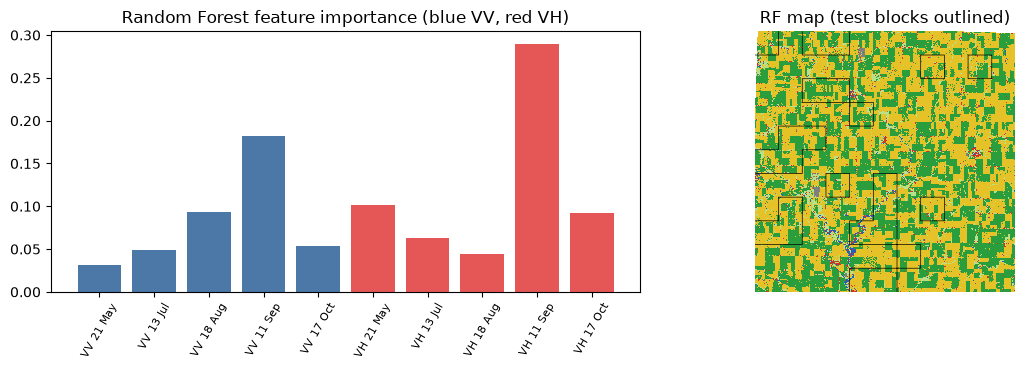

In [13]:
# importance of each of the 10 bands
imp = pd.Series(RF["mt"]["model"].model.feature_importances_, index=BAND_NAMES)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))  # two panels
ax[0].bar(range(2 * T), imp.values, color=["#4c78a8"] * T + ["#e45756"] * T); ax[0].set_xticks(range(2 * T)); ax[0].set_xticklabels(BAND_NAMES, rotation=60, fontsize=8)
ax[0].set_title("Random Forest feature importance (blue VV, red VH)")  # title
# per-class table
pc = pd.DataFrame(RF["mt"]["rep"]["per_class"]) if not isinstance(RF["mt"]["rep"]["per_class"], pd.DataFrame) else RF["mt"]["rep"]["per_class"]
print(pc.round(3).to_string())  # show it
# the RF map
ax[1].imshow(np.where(lab_s < 0, np.nan, RF["mt"]["pred"]), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest")
# test blocks outlined; title; no axes
ax[1].contour(in_te.astype(float), levels=[0.5], colors="k", linewidths=0.5); ax[1].set_title("RF map (test blocks outlined)"); ax[1].axis("off")
plt.tight_layout(); plt.show()  # arrange and draw

## CNN architectures and the mathematics behind them

`build_cnn(arch, in_channels, num_classes, pretrained=False, first_conv="mean", dropout=None, **kwargs)` returns a model whose **first layer is rebuilt for $C=10$ input channels (2 polarisations $\times$ 5 dates)**. With `pretrained=True` the RGB weights of the first convolution are averaged (`first_conv="mean"`) and replicated over the extra bands, a standard way to reuse ImageNet features for multi-channel data (here the channels are backscatter images, which look little like photographs, so ImageNet weights are of doubtful value). Here we train from scratch, which is common for small chips where the ImageNet prior is less useful. For ViT, `image_size` must match the chip size (`image_size=32`).

| Family | `arch` | Core idea |
|---|---|---|
| LeNet | `lenet` | two conv + pool stages, three fully connected layers |
| VGG-style | `vgg_small`, `simple_cnn`, `vgg11/13/16_bn` | stacked $3\times3$ convolutions + batch norm |
| ResNet | `resnet18/34/50/101` | residual (skip) connections |
| EfficientNet | `efficientnet_b0..b2`, `efficientnet_v2_s` | depth-wise separable MBConv + squeeze-excitation, compound scaling |
| ConvNeXt | `convnext_tiny/small/base` | modernised ResNet: $7\times7$ depth-wise conv, LayerNorm, inverted bottleneck |
| ViT | `vit_b_16/32` | patches $\to$ tokens $\to$ global self-attention |
| Swin | `swin_t/s`, `swin_v2_t` | shifted-window attention, hierarchical stages |

### Shared notation
A convolution with kernel $k$, stride $s$, padding $p$ maps an $H\times W$ map to

$$H'=\Big\lfloor\frac{H+2p-k}{s}+1\Big\rfloor,\qquad Z_o(i,j)=b_o+\sum_{c=1}^{C_{in}}\sum_{u,v=0}^{k-1}W_{o,c}(u,v)\,A_c(si+u-p,\,sj+v-p),$$

with $k^2C_{in}C_{out}+C_{out}$ parameters. **Batch normalisation** standardises each channel over the mini-batch, $\hat z=(z-\mu_B)/\sqrt{\sigma_B^2+\epsilon}$, then applies a learned scale and shift, $y=\gamma\hat z+\beta$. Activations are $\mathrm{ReLU}(z)=\max(0,z)$ or $\mathrm{GELU}(z)=z\,\Phi(z)$. Every classifier ends with global average pooling $\bar a_c=\frac1{HW}\sum_{i,j}A_c(i,j)$, a linear layer $\mathbf s=W\bar{\mathbf a}+\mathbf b$ and the softmax $p_k=e^{s_k}/\sum_m e^{s_m}$.


### LeNet (`lenet`)
LeNet-5 style: $\;[\text{conv}\,5{\times}5\,(C{\to}6)\to\text{ReLU}\to\text{pool}]\to[\text{conv}\,5{\times}5\,(6{\to}16)\to\text{ReLU}\to\text{pool}]\to\text{FC}\,400{\to}120\to84\to K$.

For the $32\times32$ chip: $32\xrightarrow{\text{conv},p=2}32\xrightarrow{\text{pool}}16\xrightarrow{\text{conv}}12\xrightarrow{\text{pool}}6$, then adaptive pooling to $5\times5$ gives $16\cdot5\cdot5=400$ features. Parameters with $C=10$, $K=6$:

$$(5^2\cdot10\cdot6+6)+(5^2\cdot6\cdot16+16)+(400\cdot120+120)+(120\cdot84+84)+(84\cdot6+6)=62{,}716 .$$

Two pooling stages give a receptive field of only 16 px: it cannot "see" the whole chip through convolution alone (coverage 0.5; see *Parameters and receptive field* in notebook 09_09_02_03). The large fully connected layer, not the convolutions, holds 98 % of the parameters.


### VGG-style networks (`vgg_small`, `simple_cnn`, `vgg11/13/16_bn`)
VGG replaces large filters by **stacks of $3\times3$ convolutions**. Two stacked $3\times3$ layers see a $5\times5$ neighbourhood, three see $7\times7$, but with fewer parameters and more non-linearities: $2\cdot(3^2C^2)=18C^2<25C^2$ for one $5\times5$ layer. A block is

$$\mathrm{Block}(\mathbf X)=\mathrm{MaxPool}_2\Big(\mathrm{ReLU}\big(\mathrm{BN}(W_2*\mathrm{ReLU}(\mathrm{BN}(W_1*\mathbf X)))\big)\Big),$$

with the channel width doubling per block. `vgg_small` uses widths $(32,64,128)$ and `simple_cnn` widths $(16,32)$, each followed by global average pooling, dropout and one linear layer. Because global average pooling replaces the huge VGG fully connected head, they are tiny: 290 k and 18 k parameters. The receptive field of `vgg_small` is 36 px, i.e. it covers the whole $32\times32$ chip.


### ResNet (`resnet18/34/50/101`)
Plain deep networks become hard to optimise because gradients vanish. ResNet adds an **identity shortcut** so each block learns a *residual*:

$$\mathbf y=\mathcal F(\mathbf x;\{W_i\})+\mathbf x,\qquad \frac{\partial\mathbf y}{\partial\mathbf x}=\mathbf I+\frac{\partial\mathcal F}{\partial\mathbf x}.$$

The identity term gives gradients a direct path to early layers. The *basic block* (ResNet-18/34) is $\mathcal F=\mathrm{BN}(W_2*\mathrm{ReLU}(\mathrm{BN}(W_1*\mathbf x)))$ with two $3\times3$ convolutions, followed by ReLU after the addition. ResNet-50/101 use a *bottleneck* $1{\times}1\,(C\to C/4)\to3{\times}3\to1{\times}1\,(C/4\to C)$ to cut the cost. When the shape changes, the shortcut is a strided $1\times1$ convolution $W_s\mathbf x$. ResNet-18 has 8 basic blocks in 4 stages (widths 64, 128, 256, 512; 11.2 M parameters), ResNet-34 has 16 (21.3 M). The ImageNet stem (stride-2 $7\times7$ convolution + max pool) downsamples by 4 immediately, so on a 32 px chip the last stage works on a $1\times1$ map: the network is very deep for such small inputs, which explains why ResNet-34 is not better than ResNet-18 here.


### EfficientNet (`efficientnet_b0..b2`, `efficientnet_v2_s`)
EfficientNet is built from **MBConv** blocks: an inverted bottleneck with a **depth-wise separable convolution** and **squeeze-and-excitation** (SE) channel attention. A standard $k\times k$ convolution costs $k^2C_{in}C_{out}$ multiply-adds per pixel; the separable version splits it into a depth-wise $k\times k$ convolution (one filter per channel) and a point-wise $1\times1$ convolution:

$$\underbrace{k^2C_{in}}_{\text{depth-wise}}+\underbrace{C_{in}C_{out}}_{\text{point-wise}}\;\ll\;k^2C_{in}C_{out}\quad\Big(\text{ratio }\tfrac1{C_{out}}+\tfrac1{k^2}\Big).$$

An MBConv block expands channels by a factor $t$ ($1{\times}1$), applies the depth-wise convolution, rescales channels by the SE gate $\mathbf g=\sigma\big(W_2\,\mathrm{SiLU}(W_1\,\bar{\mathbf a})\big)$ with $\bar{\mathbf a}$ the global average of each channel, projects back ($1{\times}1$) and adds a residual connection when shapes match. SiLU is $z\,\sigma(z)$. **Compound scaling** grows depth $d=\alpha^\phi$, width $w=\beta^\phi$ and resolution $r=\gamma^\phi$ together under $\alpha\beta^2\gamma^2\approx2$, so that the cost roughly doubles per unit of $\phi$. B0 has only 4 M parameters but is slower per step than ResNet-18 because depth-wise convolutions use the GPU poorly.


### ConvNeXt (`convnext_tiny/small/base`)
ConvNeXt modernises a ResNet with design choices borrowed from transformers: a "patchify" stem (stride-4 $4\times4$ convolution), a **$7\times7$ depth-wise convolution**, **LayerNorm** instead of batch norm, an **inverted bottleneck** MLP with GELU, and residual connections. One block is

$$\mathbf y=\mathbf x+\gamma\odot W_2\,\mathrm{GELU}\big(W_1\,\mathrm{LN}(\mathrm{DWConv}_{7\times7}(\mathbf x))\big),\qquad W_1:C\to4C,\; W_2:4C\to C,$$

where $\gamma$ is a learnable per-channel layer scale. LayerNorm normalises over the channel dimension of every pixel, $\hat z=(z-\mu)/\sqrt{\sigma^2+\epsilon}$, so it does not depend on the batch size. ConvNeXt-tiny has stages of depth $(3,3,9,3)$ and widths $(96,192,384,768)$ ($27.8$ M parameters). It matches transformers in large-data regimes but needs more data than a small chip set offers.


### Vision Transformer (`vit_b_16`, `vit_b_32`)
ViT drops convolution almost entirely. The image is cut into non-overlapping $P\times P$ patches, each flattened and linearly projected to a $d$-dimensional **token**; a learnable class token is prepended and position embeddings $\mathbf E_{pos}$ are added:

$$\mathbf z_0=[\mathbf x_{cls};\,\mathbf x_1W_E;\dots;\mathbf x_nW_E]+\mathbf E_{pos},\qquad n=(H/P)^2.$$

Each of $L$ encoder layers applies multi-head **self-attention** (MSA) and an MLP, each with a pre-LayerNorm and a residual connection:

$$\mathbf z'_\ell=\mathbf z_{\ell-1}+\mathrm{MSA}(\mathrm{LN}(\mathbf z_{\ell-1})),\qquad \mathbf z_\ell=\mathbf z'_\ell+\mathrm{MLP}(\mathrm{LN}(\mathbf z'_\ell)),$$

$$\mathrm{Attn}(\mathbf Q,\mathbf K,\mathbf V)=\mathrm{softmax}\!\Big(\frac{\mathbf Q\mathbf K^{\top}}{\sqrt{d_k}}\Big)\mathbf V,\quad \mathbf Q=\mathbf ZW_Q,\ \mathbf K=\mathbf ZW_K,\ \mathbf V=\mathbf ZW_V .$$

The class token after the last layer feeds the linear classifier. Every token attends to every other token, so the receptive field is global from the first layer, but there is no built-in locality or translation equivariance, so ViT needs a lot of data. With $P=16$ a $32\times32$ chip yields only $n=4$ tokens, and ViT-B has 87 M parameters: it is the heaviest and the least suited model here.


### Swin Transformer (`swin_t/s`, `swin_v2_t`)
Swin keeps the transformer but makes it hierarchical and local. Attention is computed **within non-overlapping windows** of $M\times M$ tokens, so the cost is linear in the number of tokens $N$ instead of quadratic:

$$\Omega(\mathrm{MSA})=4NC^2+2N^2C,\qquad \Omega(\mathrm{W\text{-}MSA})=4NC^2+2M^2NC .$$

Successive layers **shift** the window grid by $\lfloor M/2\rfloor$ so information flows across windows. Attention gets a learned relative position bias $B$:

$$\mathrm{Attn}=\mathrm{softmax}\!\Big(\frac{\mathbf Q\mathbf K^{\top}}{\sqrt{d_k}}+B\Big)\mathbf V .$$

Between stages, **patch merging** concatenates $2\times2$ neighbouring tokens and projects $4C\to2C$, halving the resolution like a CNN pooling layer. Swin-T uses a $4\times4$ patch embedding, depths $(2,2,6,2)$ and $27.5$ M parameters. The hierarchy gives it the multi-scale features of a CNN; on a 32 px chip, however, the token grid is only $8\times8$ and shrinks to $1\times1$.


### What the architectures share
* **Convolutional nets** (LeNet, VGG, ResNet, EfficientNet, ConvNeXt) carry the *prior* that nearby pixels matter and that features repeat across the image (translation equivariance, $f(T\mathbf x)=Tf(\mathbf x)$). That prior is a strong advantage with 13 k small training chips.
* **Residual connections** (ResNet, EfficientNet, ConvNeXt, ViT, Swin) make deep stacks trainable.
* **Normalisation** is batch norm in VGG/ResNet/EfficientNet and LayerNorm in ConvNeXt/ViT/Swin.
* **Transformers** trade the convolutional prior for global attention and need more data or pre-training.
* Cost grows from 18 k parameters (`simple_cnn`) to 87 M (`vit_b_16`), so more parameters are only worthwhile if the task is hard.


### Parameters and receptive field
`count_parameters(model)` counts trainable weights. `receptive_field(model, input_size=)` follows the conv/pool path and returns the receptive field $r$ and the jump $j$ (output stride) by the recursion

$$r_{l}=r_{l-1}+(k_l-1)\,j_{l-1},\qquad j_l=j_{l-1}\,s_l,$$

and the **coverage** $\min(1,r/\text{input size})$. A coverage below 1 means the final convolutional features cannot see the whole chip (LeNet: 16 of 32 px). Receptive fields far above 32 px (ResNet-18: 1,891 px) simply mean that the last layers see the whole padded chip. For transformers the value reflects only the patch embedding; attention is global by construction, so it is not meaningful there.


In [14]:
NC = X.shape[1]  # number of input channels (10)
# the nine architectures to compare
ARCHS = [("lenet", {}), ("simple_cnn", {}), ("vgg_small", {}), ("resnet18", {}), ("resnet34", {}),
         ("efficientnet_b0", {}), ("convnext_tiny", {}), ("vit_b_16", {"image_size": 32}), ("swin_t", {})]
rows = []  # one row per architecture
for a, kw in ARCHS:  # each one
    m = ic.build_cnn(a, in_channels=NC, num_classes=K, **kw)  # build it for ten channels and six classes
    try:
        rf_ = ic.receptive_field(m, input_size=SIZE)  # theoretical receptive field on a 32 px chip
        rf_s, cov = int(rf_["rf"]), rf_["coverage"]  # its size and coverage of the chip
    except Exception:
        rf_s, cov = None, None  # not available for this architecture
    # size and receptive field
    rows.append({"arch": a, "parameters": ic.count_parameters(m), "receptive field (px)": rf_s, "coverage of chip": cov})
arch_tab = pd.DataFrame(rows).set_index("arch")  # as a table
print(arch_tab.to_string())  # show it
x = torch.randn(4, NC, SIZE, SIZE)  # a random batch of four chips
# every model returns (4, 6) scores
print("forward pass OK for all:", all(ic.build_cnn(a, in_channels=NC, num_classes=K, **kw).eval()(x).shape == (4, K) for a, kw in ARCHS))

                 parameters  receptive field (px)  coverage of chip
arch                                                               
lenet                 62716                    16             0.500
simple_cnn            17958                    16             0.500
vgg_small            290246                    36             1.000
resnet18           11201542                  1891             1.000
resnet34           21309702                  4083             1.000
efficientnet_b0     4017250                   851             1.000
convnext_tiny      27835494                  1688             1.000
vit_b_16           87032070                    16             0.500
swin_t             27534720                     4             0.125


forward pass OK for all: True


## Data augmentation for overhead imagery

Satellite images have **no intrinsic "up"**: a field rotated by 90° is still a valid field. All 8 elements of the dihedral group $D_4$ (4 rotations $\times$ optional flip) are therefore label-preserving, in contrast to street-level photographs where only horizontal flips are. `OverheadAugment(dihedral=True, brightness, contrast, noise, crop, p, seed)` is used as the `transform` of `ChipDataset`; radiometric jitter (`brightness`, `contrast`, `noise`) should be used with care on calibrated backscatter, where a brightness shift would be read as a change of crop biomass.

**CutMix** (Yun et al., 2019) pastes a rectangular patch of chip $B$ into chip $A$ and mixes the labels in proportion to the patch area:

$$\tilde{\mathbf x}=\mathbf M\odot\mathbf x_A+(1-\mathbf M)\odot\mathbf x_B,\qquad \tilde y=\lambda\,y_A+(1-\lambda)\,y_B,\quad \lambda\sim\mathrm{Beta}(\alpha,\alpha),$$

with $\lambda$ adjusted to the exact pixel area of the paste. The loss becomes $\lambda\,\mathcal L(f(\tilde{\mathbf x}),y_A)+(1-\lambda)\,\mathcal L(f(\tilde{\mathbf x}),y_B)$. `cutmix(images, targets, alpha, rng)` returns `(mixed, y_a, y_b, lam)`; `train_model(..., cutmix_prob=p)` applies it internally.


**SAR caveat.** A radar looks to the *side* (here to the right of an ascending track), so layover, shadow and the incidence angle depend on the direction. A $90^\circ$ rotation of a whole scene would change the look direction, but at the scale of a 320 m chip of flat Corn Belt farmland the geometric effects are negligible and the dihedral group remains label-preserving. The same would not be true for mountainous terrain.


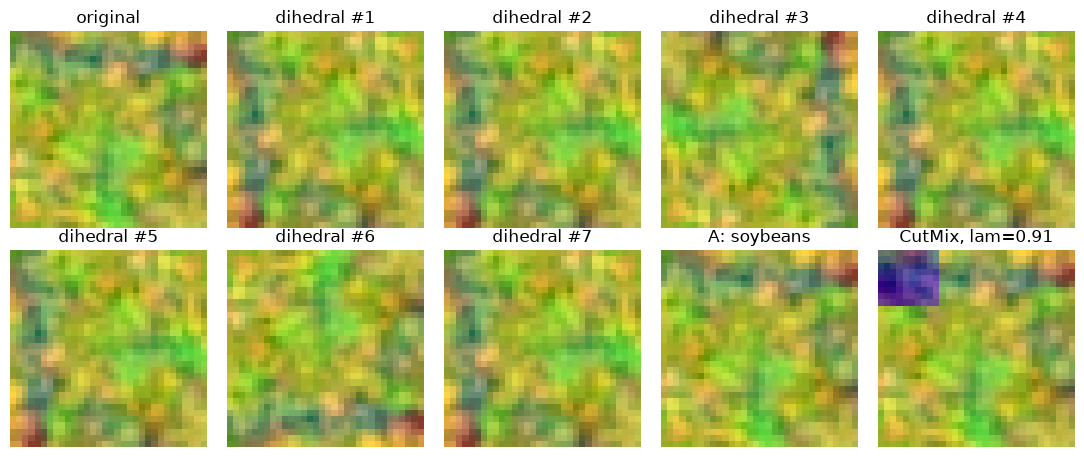

In [15]:
i0 = int(np.where(y[tr] == 1)[0][5])  # a soybean training chip
aug = ic.OverheadAugment(dihedral=True, p=1.0, seed=1)  # the eight rotations and flips
base = ic.ChipDataset(X[tr][i0:i0 + 1], y[tr][i0:i0 + 1], normalizer=norm)  # that chip, normalised
img0 = base[0]["image"]  # its tensor
vh_aug = [NC - 3, NC - 2, NC - 1]      # last three VH dates (Aug, Sep, Oct) as RGB
def show(t):  # tensor -> displayable RGB of three VH dates
    # stretch to 0-1, bands last
    a = t.numpy()[vh_aug]; a = (a - a.min()) / (a.max() - a.min() + 1e-9); return np.moveaxis(a, 0, -1)
fig, ax = plt.subplots(2, 5, figsize=(11, 4.6))  # the panels
ax[0, 0].imshow(show(img0)); ax[0, 0].set_title("original")  # the original
for k in range(1, 8):  # seven random dihedral versions
    t, _ = aug(img0.clone(), None); a = ax.flat[k]; a.imshow(show(t)); a.set_title(f"dihedral #{k}")
rng = np.random.default_rng(0)  # random generator
j_corn = int(np.where(y[tr] == 0)[0][3])  # a corn chip
# the soybean and corn chips
xb = torch.stack([base[0]["image"], ic.ChipDataset(X[tr][[j_corn]], y[tr][[j_corn]], normalizer=norm)[0]["image"]])
mixed, ya, yb, lam = ic.cutmix(xb.clone(), torch.tensor([1, 0]), alpha=1.0, rng=rng)  # CutMix of the two
# chip A and the mixed chip
ax.flat[8].imshow(show(xb[0])); ax.flat[8].set_title("A: soybeans"); ax.flat[9].imshow(show(mixed[0])); ax.flat[9].set_title(f"CutMix, lam={float(lam):.2f}")
for a in ax.flat: a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw

## Loss functions: cross-entropy, weighted, focal and label smoothing

For logits $\mathbf z$ and softmax probabilities $p_k=e^{z_k}/\sum_j e^{z_j}$ with one-hot target $y$:

* **Cross-entropy:** $\mathcal L_{\text{CE}}=-\log p_y$.
* **Weighted CE:** $\mathcal L=-w_y\log p_y$ with $w$ from `class_weights`; minority errors cost more.
* **Label smoothing** $\varepsilon$: replace the one-hot target by $(1-\varepsilon)\,\mathbb 1_y+\varepsilon/K$, giving $\mathcal L=-(1-\varepsilon)\log p_y-\frac{\varepsilon}{K}\sum_k\log p_k$. It prevents over-confident logits and helps when the labels are noisy; CDL is itself a model product with about 5-15 % class-specific error, so some label noise is certain.
* **Focal loss** (Lin et al., 2017): $\mathcal L_{\text{focal}}=-\alpha_y\,(1-p_y)^{\gamma}\log p_y$. The modulating factor $(1-p_y)^\gamma$ down-weights easy examples ($p_y\to1$) so that training focuses on hard, often minority-class examples; $\gamma=2$ is the usual choice.

All losses accept $(N,C)$ logits with $(N,)$ targets. Quick numerical check on one batch:


{'ce': 3.1363, 'weighted_ce': 3.3365, 'focal (g=2)': 2.8576, 'focal + weights': 2.9168, 'label smoothing 0.1': 3.1391}


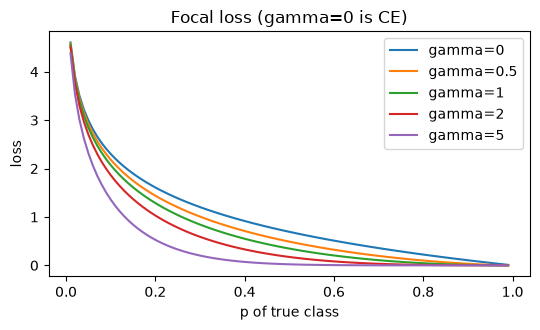

In [16]:
zb = torch.randn(256, K) * 2; yb_ = torch.randint(0, K, (256,))  # random scores and labels for 256 samples
cw = W_["sqrt_inverse"]  # square-root inverse class weights
losses = {"ce": ic.get_loss("ce"), "weighted_ce": ic.get_loss("weighted_ce", class_weights=cw),  # five losses
          "focal (g=2)": ic.get_loss("focal", gamma=2.0), "focal + weights": ic.get_loss("focal", gamma=2.0, class_weights=cw),
          "label smoothing 0.1": ic.get_loss("ce", label_smoothing=0.1)}
print({k: round(float(f(zb, yb_)), 4) for k, f in losses.items()})  # loss of each on the same batch
p = torch.linspace(0.01, 0.99, 99)  # probabilities of the true class
plt.figure(figsize=(5.5, 3.4))  # one panel
# focal loss for several gamma values
for g in (0, 0.5, 1, 2, 5): plt.plot(p, -(1 - p) ** g * torch.log(p), label=f"gamma={g}")
# labels, title, legend and draw
plt.xlabel("p of true class"); plt.ylabel("loss"); plt.title("Focal loss (gamma=0 is CE)"); plt.legend(); plt.tight_layout(); plt.show()

## Training and experiments: architectures, SAR inputs, augmentation and losses

### The training loop: `train_model`

`train_model(model, train_loader, val_loader, task="classification", epochs, loss, optimizer, lr, weight_decay, scheduler, precision, grad_clip, early_stopping, monitor, checkpoint, seed, num_classes, cutmix_prob, logger, log_dir, ...)` is an explicit PyTorch loop that implements:

* **AdamW** (decoupled weight decay): $\theta\leftarrow\theta-\eta\Big(\dfrac{\hat m_t}{\sqrt{\hat v_t}+\epsilon}+\lambda\theta\Big)$ with first/second moment estimates $m_t,v_t$;
* **Cosine schedule:** $\eta_t=\tfrac12\eta_0\big(1+\cos(\pi t/T)\big)$, annealing the learning rate smoothly to zero; `onecycle`, `step` and `plateau` are alternatives;
* **Mixed precision** (`precision="16"` with gradient scaling, or `"bf16"`): forward/backward in half precision on the GPU for speed and memory, master weights in float32;
* **Gradient clipping:** $\mathbf g\leftarrow\mathbf g\cdot\min\!\big(1,\,c/\lVert\mathbf g\rVert_2\big)$ with $c$ = `grad_clip`;
* **Early stopping** on `monitor` (`val_loss` or `val_score` = accuracy) with patience, and **restoring of the best weights**;
* **Checkpoint** of the best state and **logging** to TensorBoard (or W&B, MLflow, or any callable).

It returns a history dict (`train_loss`, `val_loss`, `val_score`, `lr`). The helper below wraps one experiment: it builds the datasets, trains, and scores the test blocks. Model selection uses the **validation** set only; the test set is touched once per run for reporting.


In [17]:
def prob_to_report(P, yt, n_boot=0):  # accuracy report from class probabilities
    # most probable class against the labels
    return ic.classification_report(yt, P.argmax(1), labels=list(range(K)), class_names=dict(enumerate(CLASSES)), n_boot=n_boot, seed=0)

NORMS = {}  # normalisers per input version and channel set
# train one model and score it
def fit(arch, *, seed=0, epochs=12, loss="ce", aug=None, cutmix=0.0, lr=1e-3, wd=1e-4, kw=None, precision="16",
        cw=None, label_smoothing=0.0, early=None, checkpoint=None, logger=None, log_dir=None, tta=False,
        variant="mt", chan=None):
    """Train one model. `variant` picks the input processing (mt/lee/raw), `chan` a subset of the 10 channels."""
    ic.set_seed(seed)  # same initial weights for a given seed
    ch = list(range(NC)) if chan is None else list(chan)  # channels to use (all by default)
    Xv = XV[variant][:, ch]  # chips of the chosen version and channels
    key = (variant, tuple(ch))  # cache key of the normaliser
    if key not in NORMS:  # not fitted yet
        NORMS[key] = ic.Normalizer("zscore").fit(Xv[tr], band_axis=1)  # fit it on the training chips
    nm = NORMS[key]  # the normaliser
    # chip dataset of indices idx
    mk_ = lambda idx, tf=None: ic.ChipDataset(Xv[idx], y[idx], normalizer=nm, transform=tf)
    # optional rotation and flip augmentation
    tf = None if aug is None else ic.OverheadAugment(dihedral=True, p=1.0, seed=seed)
    ltr = ic.as_loader(mk_(tr, tf), 128, shuffle=True, seed=seed)  # shuffled training batches
    # validation and test batches
    lva, lte = ic.as_loader(mk_(va), 256, shuffle=False), ic.as_loader(mk_(te), 256, shuffle=False)
    model = ic.build_cnn(arch, in_channels=len(ch), num_classes=K, **(kw or {}))  # the network
    lf = ic.get_loss(loss, class_weights=cw, label_smoothing=label_smoothing)  # the loss
    t0 = time.time()  # start the timer
    # the GeoLattice training loop
    hist = ic.train_model(model, ltr, lva, task="classification", epochs=epochs, loss=lf, optimizer="adamw", lr=lr,
                          weight_decay=wd, scheduler="cosine", precision=precision if DEVICE == "cuda" else "32", grad_clip=1.0,
                          early_stopping=early, monitor="val_score", checkpoint=checkpoint, seed=seed, num_classes=K,
                          cutmix_prob=cutmix, logger=logger, log_dir=log_dir, device=DEVICE, verbose=False)
    sec = time.time() - t0  # training time
    Pv = ic.predict_proba_batches(model, lva, device=DEVICE)  # validation probabilities
    # test probabilities (optionally with test-time augmentation)
    Pt = ic.predict_proba_batches(model, lte, device=DEVICE, tta=tta)
    # model, history, time, scores and normaliser
    return dict(model=model, hist=hist, sec=sec, val_acc=float((Pv.argmax(1) == y[va]).mean()),
                test_acc=float((Pt.argmax(1) == y[te]).mean()), P=Pt, norm=nm)

### Benchmarking the nine architectures under one recipe
Every architecture is trained with the **same** recipe (AdamW, lr $10^{-3}$, cosine, AMP, grad-clip 1, plain CE, no augmentation) on the multi-temporal-filtered 10-channel chips for a fixed number of epochs, with one seed per architecture; the seeds are repeated for the ablations that follow. Parameters and receptive field are from the *Parameters and receptive field* section.


In [18]:
# smaller learning rates for transformers and ConvNeXt
lr_by = {"vit_b_16": 3e-4, "swin_t": 3e-4, "convnext_tiny": 5e-4}
res_arch, rows = {}, []  # results and rows
for a, kw in ARCHS:  # each architecture
    r = fit(a, seed=0, epochs=EPOCHS_ARCH, lr=lr_by.get(a, 1e-3), kw=kw)  # train it
    res_arch[a] = r  # keep it
    rep_a = prob_to_report(r["P"], y[te])  # its test report
    # size, speed and accuracy
    rows.append({"arch": a, "parameters": arch_tab.loc[a, "parameters"], "receptive field": arch_tab.loc[a, "receptive field (px)"],
                 "sec/epoch": r["sec"] / EPOCHS_ARCH, "best val acc": max(r["hist"]["val_score"]), "test acc": r["test_acc"], "macro F1": rep_a["macro_f1"]})
    # progress line
    print(f"{a:16s} val {rows[-1]['best val acc']:.4f}  test {r['test_acc']:.4f}  ({r['sec']:.0f}s)")
arch_res = pd.DataFrame(rows).set_index("arch").round(4)  # as a table
arch_res  # show it

lenet            val 0.9894  test 0.9925  (15s)


simple_cnn       val 0.9975  test 0.9961  (12s)


vgg_small        val 0.9969  test 0.9939  (13s)


resnet18         val 0.9955  test 0.9939  (20s)


resnet34         val 0.9944  test 0.9927  (30s)


efficientnet_b0  val 0.9951  test 0.9941  (43s)


convnext_tiny    val 0.9899  test 0.9884  (43s)


vit_b_16         val 0.9899  test 0.9884  (84s)


swin_t           val 0.9874  test 0.9868  (87s)


,parameters,receptive field,sec/epoch,best val acc,test acc,macro F1
arch,,,,,,
lenet,62716,16,0.9690,0.9894,0.9925,0.9682
simple_cnn,17958,16,0.7690,0.9975,0.9961,0.9975
vgg_small,290246,36,0.8857,0.9969,0.9939,0.9928
resnet18,11201542,1891,1.3357,0.9955,0.9939,0.9851
resnet34,21309702,4083,1.9838,0.9944,0.9927,0.9839
efficientnet_b0,4017250,851,2.8402,0.9951,0.9941,0.9911
convnext_tiny,27835494,1688,2.8824,0.9899,0.9884,0.9529
vit_b_16,87032070,16,5.6119,0.9899,0.9884,0.9695
swin_t,27534720,4,5.8331,0.9874,0.9868,0.9802


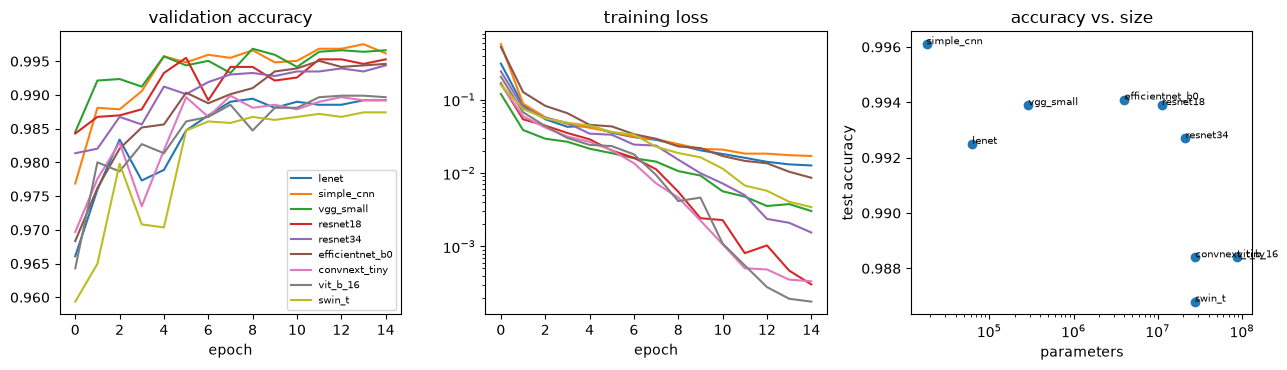

In [19]:
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8))  # three panels
for a, r in res_arch.items():  # each architecture
    ax[0].plot(r["hist"]["val_score"], label=a)  # its validation accuracy
    ax[1].plot(r["hist"]["train_loss"], label=a)  # its training loss
# titles, log scale and legend
ax[0].set_title("validation accuracy"); ax[1].set_title("training loss"); ax[1].set_yscale("log"); ax[0].legend(fontsize=7)
for a in ax[:2]: a.set_xlabel("epoch")  # epoch axes
ax[2].scatter(arch_res["parameters"], arch_res["test acc"], c="C0")  # accuracy against size
# architecture names
for a, r in arch_res.iterrows(): ax[2].annotate(a, (r["parameters"], r["test acc"]), fontsize=7)
# log axis, labels and title
ax[2].set_xscale("log"); ax[2].set_xlabel("parameters"); ax[2].set_ylabel("test accuracy"); ax[2].set_title("accuracy vs. size")
plt.tight_layout(); plt.show()  # arrange and draw

### Which SAR information matters? Input ablations on ResNet-18 (mean ± SD over seeds)
We fix **ResNet-18** and change only the *input*, repeating each configuration over seeds $\{0,1,2\}$. Differences smaller than about one SD should not be interpreted.

* **Speckle treatment:** raw dB, single-date Lee, multi-temporal Lee (the default).
* **Polarisation:** VV only (5 channels), VH only (5 channels), both (10).
* **Date removed (leave-one-date-out):** the drop in accuracy when one acquisition is withheld measures how much *unique* information that date carries.
* **Season so far (cumulative dates):** how early in the season could a map have been made? With only the 21 May scene (bare soil, before emergence) the classes should be close to inseparable.


In [20]:
VVc, VHc = list(range(T)), list(range(T, 2 * T))  # VV and VH channel indices
def drop_date(t): return [c for c in range(NC) if c % T != t]  # all channels except one date
def upto(n): return [c for c in range(NC) if c % T < n]  # only the first n dates
abl_cfg = {  # input variants of the ablation
    "raw dB (no filter)":            dict(variant="raw"),
    "single-date Lee":               dict(variant="lee"),
    "multi-temporal Lee (default)":  dict(variant="mt"),
    "VV only":                       dict(chan=VVc),
    "VH only":                       dict(chan=VHc),
}
for t in range(T):  # each date ...
    abl_cfg[f"without {DLAB[t]}"] = dict(chan=drop_date(t))  # ... left out once
for n in range(1, T):  # the first 1, 2, 3 and 4 dates
    abl_cfg[f"dates 1-{n} (to {DLAB[n - 1]})"] = dict(chan=upto(n))  # ... (early-season maps)

rows = []  # one row per run
for name, cfg in abl_cfg.items():  # each variant
    for s in SEEDS:  # each seed
        r = fit("resnet18", seed=s, epochs=EPOCHS_ABL, **cfg)  # train ResNet-18
        rrep = prob_to_report(r["P"], y[te])  # test report
        # the scores
        rows.append(dict(config=name, seed=s, val_acc=r["val_acc"], test_acc=r["test_acc"], macro_f1=rrep["macro_f1"], sec=r["sec"]))
    print(name, "done")  # progress
abl_in = pd.DataFrame(rows)  # as a table
# mean and spread per variant
tab_in = abl_in.groupby("config", sort=False).agg(val_acc=("val_acc", "mean"), test_acc=("test_acc", "mean"), test_sd=("test_acc", "std"),
                                                  macro_f1=("macro_f1", "mean"), macro_f1_sd=("macro_f1", "std")).round(4)
tab_in  # show it

raw dB (no filter) done


single-date Lee done


multi-temporal Lee (default) done


VV only done


VH only done


without 21 May done


... (5 outputs left out)

dates 1-2 (to 13 Jul) done


dates 1-3 (to 18 Aug) done


dates 1-4 (to 11 Sep) done


,val_acc,test_acc,test_sd,macro_f1,macro_f1_sd
config,,,,,
raw dB (no filter),0.9939,0.9933,0.0016,0.9802,0.0037
single-date Lee,0.9946,0.9936,0.0009,0.9663,0.0141
multi-temporal Lee (default),0.9942,0.9919,0.0006,0.9763,0.0050
VV only,0.9823,0.9856,0.0024,0.8887,0.0473
VH only,0.9948,0.9934,0.0004,0.9600,0.0470
without 21 May,0.9934,0.9925,0.0010,0.9686,0.0112
without 13 Jul,0.9949,0.9968,0.0006,0.9829,0.0075
without 18 Aug,0.9942,0.9909,0.0024,0.9721,0.0082
without 11 Sep,0.9802,0.9792,0.0034,0.9416,0.0553


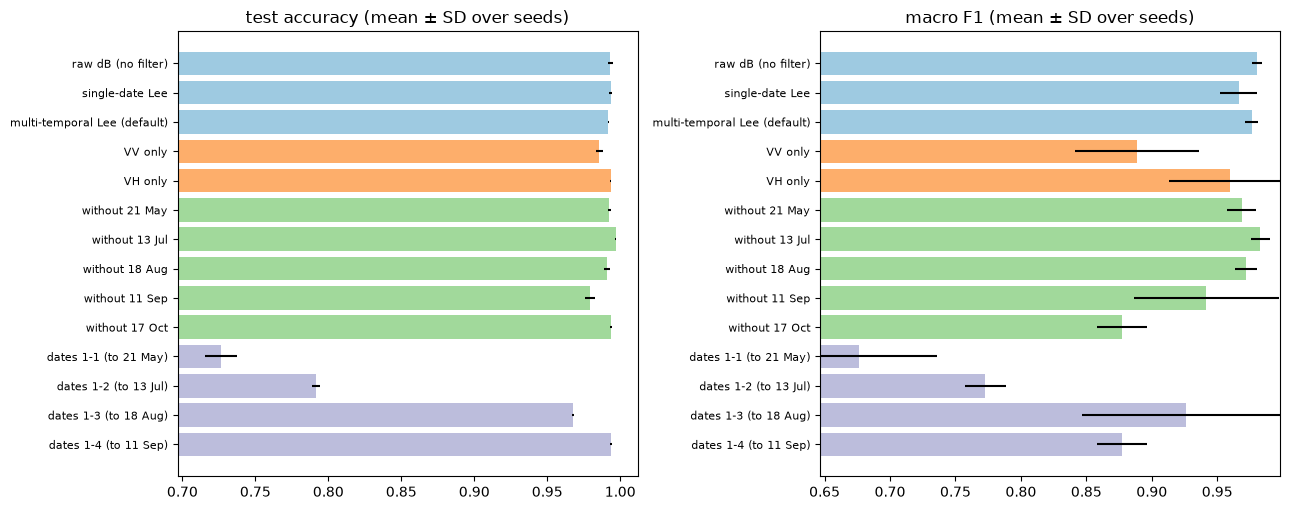

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5.2))  # two panels
g = abl_in.groupby("config", sort=False)  # runs grouped by variant
# accuracy and macro F1
for a, col, t in [(ax[0], "test_acc", "test accuracy"), (ax[1], "macro_f1", "macro F1")]:
    m_, s_ = g[col].mean(), g[col].std()  # mean and spread
    cols = ["#9ecae1" if n.startswith(("raw", "single", "multi")) else "#fdae6b" if n.endswith("only") else "#a1d99b" if n.startswith("without") else "#bcbddc" for n in m_.index]
    # bars with names
    a.barh(range(len(m_)), m_, xerr=s_, color=cols); a.set_yticks(range(len(m_))); a.set_yticklabels(m_.index, fontsize=8)
    # limits, title, top-to-bottom order
    a.set_xlim(m_.min() - 0.03, m_.max() + 0.015); a.set_title(f"{t} (mean ± SD over seeds)"); a.invert_yaxis()
plt.tight_layout(); plt.show()  # arrange and draw

### Augmentation and loss ablations on ResNet-18 (mean ± SD over seeds)
The same repeated-seed protocol, now varying one *training* ingredient at a time on the default multi-temporal-filtered input.


In [22]:
CW = W_["sqrt_inverse"]  # the class weights used below
configs = {  # eight training variants of ResNet-18
    "baseline (CE)":              dict(),
    "+ OverheadAugment":          dict(aug=True),
    "+ CutMix (p=0.5)":           dict(cutmix=0.5),
    "+ Aug + CutMix":             dict(aug=True, cutmix=0.5),
    "weighted CE (sqrt-inv.)":    dict(loss="weighted_ce", cw=CW),
    "focal (gamma=2)":            dict(loss="focal"),
    "focal + weights":            dict(loss="focal", cw=CW),
    "label smoothing 0.1":        dict(label_smoothing=0.1),
}
rows = []  # one row per run
for name, cfg in configs.items():  # each variant
    for s in SEEDS:  # each seed
        # the augmentation flag -> an OverheadAugment class
        c = dict(cfg); c["aug"] = ic.OverheadAugment if c.pop("aug", False) else None
        r = fit("resnet18", seed=s, epochs=EPOCHS_ABL, **c)  # train it
        rrep = prob_to_report(r["P"], y[te])  # test report
        # the scores
        rows.append(dict(config=name, seed=s, val_acc=r["val_acc"], test_acc=r["test_acc"], macro_f1=rrep["macro_f1"], sec=r["sec"]))
    print(name, "done")  # progress
abl = pd.DataFrame(rows)  # as a table
# mean and spread per variant
tab = abl.groupby("config", sort=False).agg(val_acc=("val_acc", "mean"), test_acc=("test_acc", "mean"), test_sd=("test_acc", "std"),
                                            macro_f1=("macro_f1", "mean"), macro_f1_sd=("macro_f1", "std"), sec=("sec", "mean")).round(4)
tab  # show it

baseline (CE) done


+ OverheadAugment done


+ CutMix (p=0.5) done


+ Aug + CutMix done


weighted CE (sqrt-inv.) done


focal (gamma=2) done


focal + weights done


label smoothing 0.1 done


,val_acc,test_acc,test_sd,macro_f1,macro_f1_sd,sec
config,,,,,,
baseline (CE),0.9942,0.9919,0.0006,0.9763,0.0050,16.1037
+ OverheadAugment,0.9969,0.9948,0.0007,0.9902,0.0121,18.5143
+ CutMix (p=0.5),0.9973,0.9954,0.0009,0.9809,0.0163,16.5247
+ Aug + CutMix,0.9975,0.9947,0.0009,0.9927,0.0045,18.8405
weighted CE (sqrt-inv.),0.9943,0.9928,0.0018,0.9329,0.0690,16.0501
focal (gamma=2),0.9950,0.9925,0.0006,0.9822,0.0086,16.7649
focal + weights,0.9939,0.9919,0.0009,0.9740,0.0017,17.0256
label smoothing 0.1,0.9951,0.9932,0.0018,0.9767,0.0138,16.2343


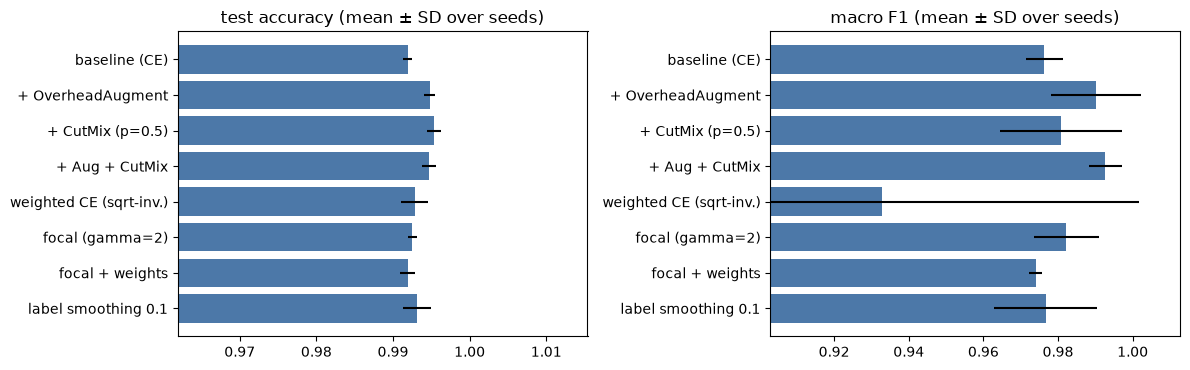

In [23]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))  # two panels
# test accuracy and macro F1
for a, col, t in [(ax[0], "test_acc", "test accuracy"), (ax[1], "macro_f1", "macro F1")]:
    g = abl.groupby("config", sort=False)[col]  # runs grouped by variant
    a.barh(range(len(g.mean())), g.mean(), xerr=g.std(), color="#4c78a8"); a.set_yticks(range(len(g.mean()))); a.set_yticklabels(g.mean().index)
    # limits, title, top-to-bottom order
    a.set_xlim(g.mean().min() - 0.03, g.mean().max() + 0.02); a.set_title(f"{t} (mean ± SD over seeds)"); a.invert_yaxis()
plt.tight_layout(); plt.show()  # arrange and draw

## Final model: early stopping, checkpoint and TensorBoard

We train the final model with everything switched on: AdamW + cosine schedule, mixed precision, gradient clipping, **early stopping** (patience 6 on validation accuracy), best-weights **checkpoint** and **TensorBoard** logging (guarded in case it is not installed). The best training configuration in the *Augmentation and loss ablations on ResNet-18 (mean ± SD over seeds)* section is selected on the **validation** accuracy (not the test accuracy) and the final training is longer than the ablation runs.


config selected on validation accuracy: + Aug + CutMix


I0000 00:00:1793594373.548200  397402 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793594373.579112  397402 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1793594375.981367  397402 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


stopped after 18 epochs | best val acc 0.9984 | test acc 0.9952 | checkpoint resnet18_best.pt (44.9 MB) | logger: tensorboard
TensorBoard event files: ['events.out.tfevents.1793594376.zia207-ThinkPad-P16-Gen-1.397402.0']


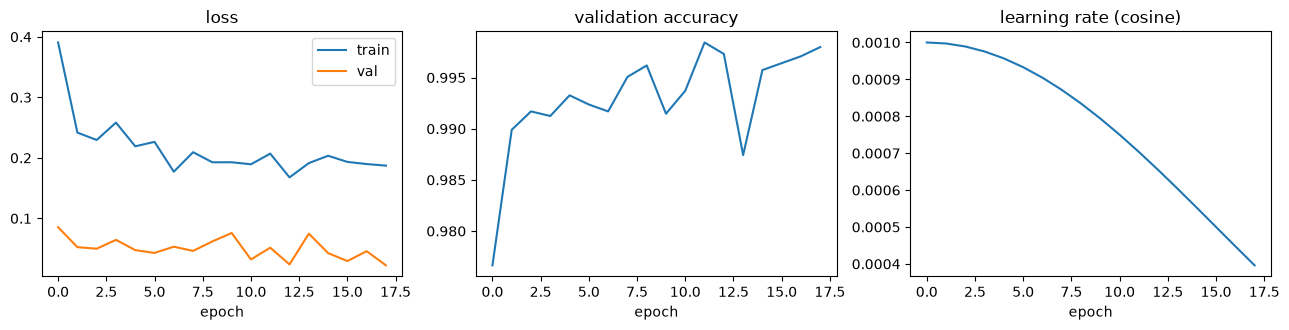

In [24]:
# the variant with the best validation accuracy
best_cfg = abl.groupby("config", sort=False)["val_acc"].mean().idxmax()
print("config selected on validation accuracy:", best_cfg)  # report it
# its settings
cfg = dict(configs[best_cfg]); cfg["aug"] = ic.OverheadAugment if cfg.pop("aug", False) else None

try:
    import tensorboard  # noqa
    LOGGER = "tensorboard"  # TensorBoard is installed
except ImportError:
    LOGGER = None  # no logger
OUT = Path(tempfile.mkdtemp(prefix="s1_cnn_"))  # a temporary output folder
CKPT = OUT / "resnet18_best.pt"  # the checkpoint file
# train the final model with early stopping and a checkpoint
final = fit("resnet18", seed=SEED, epochs=int(30 * SCALE) if DEVICE == "cuda" else 6, early=6, checkpoint=CKPT,
            logger=LOGGER, log_dir=str(OUT / "tb"), **cfg)
h = final["hist"]  # its history
# epochs, scores and checkpoint size
print(f"stopped after {len(h['val_score'])} epochs | best val acc {max(h['val_score']):.4f} | test acc {final['test_acc']:.4f} | "
      f"checkpoint {CKPT.name} ({CKPT.stat().st_size / 1e6:.1f} MB) | logger: {LOGGER}")
# the TensorBoard files
print("TensorBoard event files:", sorted(p.name for p in (OUT / "tb").rglob("events*"))[:2] if LOGGER else "n/a")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.4))  # three panels
# loss curves
ax[0].plot(h["train_loss"], label="train"); ax[0].plot(h["val_loss"], label="val"); ax[0].set_title("loss"); ax[0].legend()
# validation accuracy and learning rate
ax[1].plot(h["val_score"]); ax[1].set_title("validation accuracy"); ax[2].plot(h["lr"]); ax[2].set_title("learning rate (cosine)")
for a in ax: a.set_xlabel("epoch")  # epoch axes
plt.tight_layout(); plt.show()  # arrange and draw

### Restoring the model with `load_checkpoint`
`load_checkpoint(model, path)` loads the saved weights into a **freshly built** model of the same architecture and returns `(model, missing_keys)`. A correct round trip reproduces the predictions exactly.


In [25]:
fresh = ic.build_cnn("resnet18", in_channels=NC, num_classes=K)  # a fresh ResNet-18
fresh, missing = ic.load_checkpoint(fresh, CKPT)  # load the saved weights
P_fresh = ic.predict_proba_batches(fresh, ld_te, device=DEVICE)  # test probabilities of the reloaded model
# missing keys and the largest difference
print("load_state_dict:", missing, "| max |p_trained - p_reloaded| =", float(np.abs(P_fresh - final["P"]).max()))

load_state_dict: <All keys matched successfully> | max |p_trained - p_reloaded| = 0.0


## Inference and evaluation: chips, wall-to-wall map and field boundaries

### Chip-level evaluation: probabilities, TTA, bootstrap metrics and confusion matrix

* `predict_proba_batches(model, data, tta=False)` returns softmax probabilities in batches; `tta=True` averages the 8 dihedral transforms (**test-time augmentation**), $\bar p=\frac18\sum_{g\in D_4}p(g\cdot\mathbf x)$, the inference counterpart of `OverheadAugment`.
* `classification_report(y_true, y_pred, labels, class_names, n_boot)` gives overall accuracy, Cohen's $\kappa$, macro-F1, per-class precision/recall/F1 and a **bootstrap confidence interval** (resampling test chips with replacement).

Because chips in a block are spatially autocorrelated, the bootstrap interval is somewhat optimistic; the SD over seeds in the *Pixel-based baseline: Random Forest on the temporal profile* section is a complementary uncertainty measure.


In [26]:
P_plain = ic.predict_proba_batches(final["model"], ld_te, device=DEVICE)  # test probabilities without TTA
# and with the eight rotations and flips averaged
P_tta = ic.predict_proba_batches(final["model"], ld_te, device=DEVICE, tta=True)
yt = y[te]  # test labels
# accuracy report of the TTA predictions
rep = ic.classification_report(yt, P_tta.argmax(1), labels=list(range(K)), class_names=dict(enumerate(CLASSES)), n_boot=300, seed=0)
# both accuracies
print(f"plain  OA {(P_plain.argmax(1) == yt).mean():.4f} | TTA (8 dihedral) OA {(P_tta.argmax(1) == yt).mean():.4f}")
# headline scores
print(f"overall accuracy {rep['overall_accuracy']:.4f} | kappa {rep['kappa']:.4f} | macro-F1 {rep['macro_f1']:.4f} | n = {rep['n']:,}")
# bootstrap intervals
print("bootstrap 95% CI:", {k: tuple(round(float(x), 4) for x in v) for k, v in rep["ci"].items()} if isinstance(rep["ci"], dict) else rep["ci"])
pc = rep["per_class"]  # per-class scores
print(pd.DataFrame(pc).round(3) if not isinstance(pc, pd.DataFrame) else pc.round(3))  # show them

plain  OA 0.9952 | TTA (8 dihedral) OA 0.9952
overall accuracy 0.9952 | kappa 0.9903 | macro-F1 0.9916 | n = 4,400
bootstrap 95% CI: {'oa': (0.9934, 0.997), 'kappa': (0.9866, 0.994), 'macro_f1': (0.9782, 0.998)}
                precision  recall     f1  support  f1_ci_low  f1_ci_high
Corn                0.995   0.997  0.996     2540      0.995       0.998
Soybeans            0.996   0.993  0.995     1828      0.992       0.997
Grass/pasture       0.969   1.000  0.984       31      0.945       1.000
Developed           0.000     NaN    NaN        0        NaN         NaN
Wetland/forest        NaN   0.000    NaN        1        NaN         NaN
Other                 NaN     NaN    NaN        0        NaN         NaN


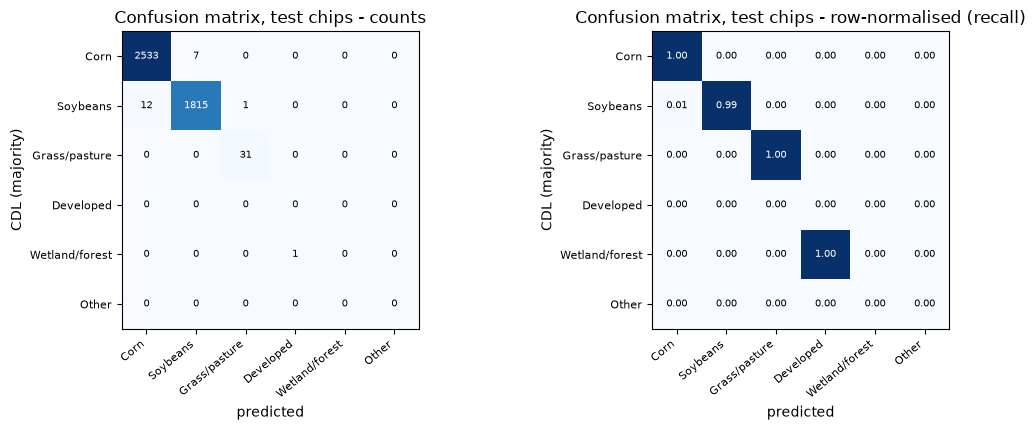

In [27]:
cmx = np.asarray(rep["confusion_matrix"])  # the confusion matrix
fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))  # two panels
# counts and row shares
for a, M, t, f in [(ax[0], cmx, "counts", "d"), (ax[1], cmx / np.maximum(cmx.sum(1, keepdims=True), 1), "row-normalised (recall)", ".2f")]:
    im = a.imshow(M, cmap="Blues"); a.set_xticks(range(K)); a.set_yticks(range(K))  # the matrix
    # class names
    a.set_xticklabels(CLASSES, rotation=40, ha="right", fontsize=8); a.set_yticklabels(CLASSES, fontsize=8)
    for i in range(K):  # every cell ...
        for j in range(K):  # ...
            # its value
            a.text(j, i, format(M[i, j], f), ha="center", va="center", fontsize=7, color="w" if M[i, j] > M.max() / 2 else "k")
    # title and axis labels
    a.set_title(f"Confusion matrix, test chips - {t}"); a.set_xlabel("predicted"); a.set_ylabel("CDL (majority)")
plt.tight_layout(); plt.show()  # arrange and draw

### Wall-to-wall prediction map with `predict_chip_map`
`predict_chip_map(model, image, size=, stride=, normalizer=, batch_size=)` slides the chip classifier over a georeferenced image and assigns each pixel the class of the chip whose centre is nearest (stride 8 here; each pixel then comes from a chip centred within 4 px). Chips with `NaN` get nodata $-1$ (radar has no clouds, so there are none here). The normaliser is the one fitted on the training chips. We also compare with the pixel Random Forest of the *Pixel-based baseline: Random Forest on the temporal profile* section on the same test pixels, which is the fair answer to *what does the neighbourhood add?* We evaluate the map **only on pixels inside test blocks**, comparing with the original 10 m CDL pixels (not the chip majority labels), which is the number a map user actually experiences.


map (2816, 2816) in 16 s
CNN (ResNet-18) pixel-level OA on test blocks vs. CDL: 0.8798 | kappa 0.7817 | macro-F1 0.4557 | pixels 1,563,711
RF pixel baseline on the same blocks:           OA 0.8892 | kappa 0.8050 | macro-F1 0.5406


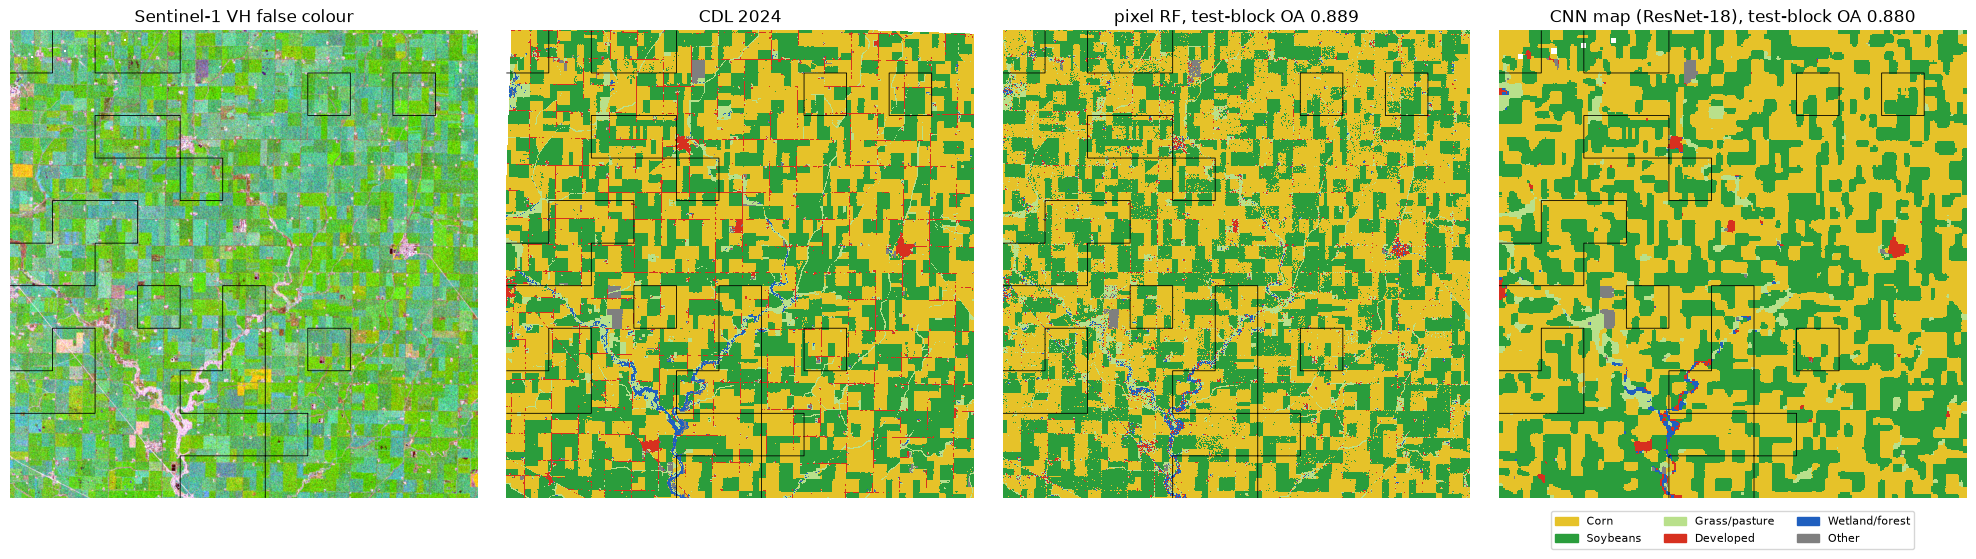

                RF pixel F1  CNN map F1
Corn                  0.932       0.924
Soybeans              0.932       0.914
Grass/pasture         0.549       0.441
Developed             0.207       0.053
Wetland/forest        0.498       0.358
Other                 0.125       0.044


In [28]:
sub = IMG["mt"].isel(y=SUB, x=SUB)  # the area covered by blocks
t0 = time.time()  # start the timer
# class map from a sliding 32 px window
pm = ic.predict_chip_map(final["model"], sub, size=SIZE, stride=8, normalizer=final["norm"], batch_size=512, device=DEVICE)
pred = pm.values.astype(int); print(f"map {pred.shape} in {time.time() - t0:.0f} s")  # as integers; time
is_te = in_te; ref_l = lab_s  # test-block mask and reference labels
m = is_te & (pred >= 0) & (ref_l >= 0)  # test pixels with a prediction and a label
oa_px = (pred[m] == ref_l[m]).mean()  # pixel accuracy
# pixel accuracy report
rep_px = ic.classification_report(ref_l[m], pred[m], labels=list(range(K)), class_names=dict(enumerate(CLASSES)), n_boot=0)
rf_m = RF["mt"]["mask"]  # the RF evaluation mask
# CNN scores
print(f"CNN (ResNet-18) pixel-level OA on test blocks vs. CDL: {oa_px:.4f} | kappa {rep_px['kappa']:.4f} | macro-F1 {rep_px['macro_f1']:.4f} | pixels {m.sum():,}")
# RF scores on the same blocks
print(f"RF pixel baseline on the same blocks:           OA {RF['mt']['rep']['overall_accuracy']:.4f} | kappa {RF['mt']['rep']['kappa']:.4f} | macro-F1 {RF['mt']['rep']['macro_f1']:.4f}")

fig, ax = plt.subplots(1, 4, figsize=(20, 5.4))  # four panels
sh = lambda a: np.where(a < 0, np.nan, a)  # negative ids as missing
ax[0].imshow(rgbimg[:nb * BLOCK, :nb * BLOCK]); ax[0].set_title("Sentinel-1 VH false colour")  # VH composite
# CDL
ax[1].imshow(sh(ref_l), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[1].set_title("CDL 2024")
# RF map
ax[2].imshow(sh(RF["mt"]["pred"]), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[2].set_title(f"pixel RF, test-block OA {RF['mt']['rep']['overall_accuracy']:.3f}")
# CNN map
ax[3].imshow(sh(pred), cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[3].set_title(f"CNN map (ResNet-18), test-block OA {oa_px:.3f}")
for a in ax:  # every panel
    # no axes; test blocks outlined
    a.axis("off"); a.contour(is_te.astype(float), levels=[0.5], colors="k", linewidths=0.6)
# class legend
ax[3].legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c) for c in COLORS], labels=CLASSES, loc="lower center", ncol=3, fontsize=8, bbox_to_anchor=(0.5, -0.12))
plt.tight_layout(); plt.show()  # arrange and draw

# per-class F1 of both maps
pf = pd.DataFrame({"RF pixel F1": pd.Series(RF["mt"]["rep"]["per_class"]["f1"] if isinstance(RF["mt"]["rep"]["per_class"], dict) else RF["mt"]["rep"]["per_class"]["f1"]).values,
                   "CNN map F1": pd.Series(rep_px["per_class"]["f1"]).values}, index=CLASSES).round(3)
print(pf.to_string())  # show it

### Where is the map wrong? Errors versus field boundaries


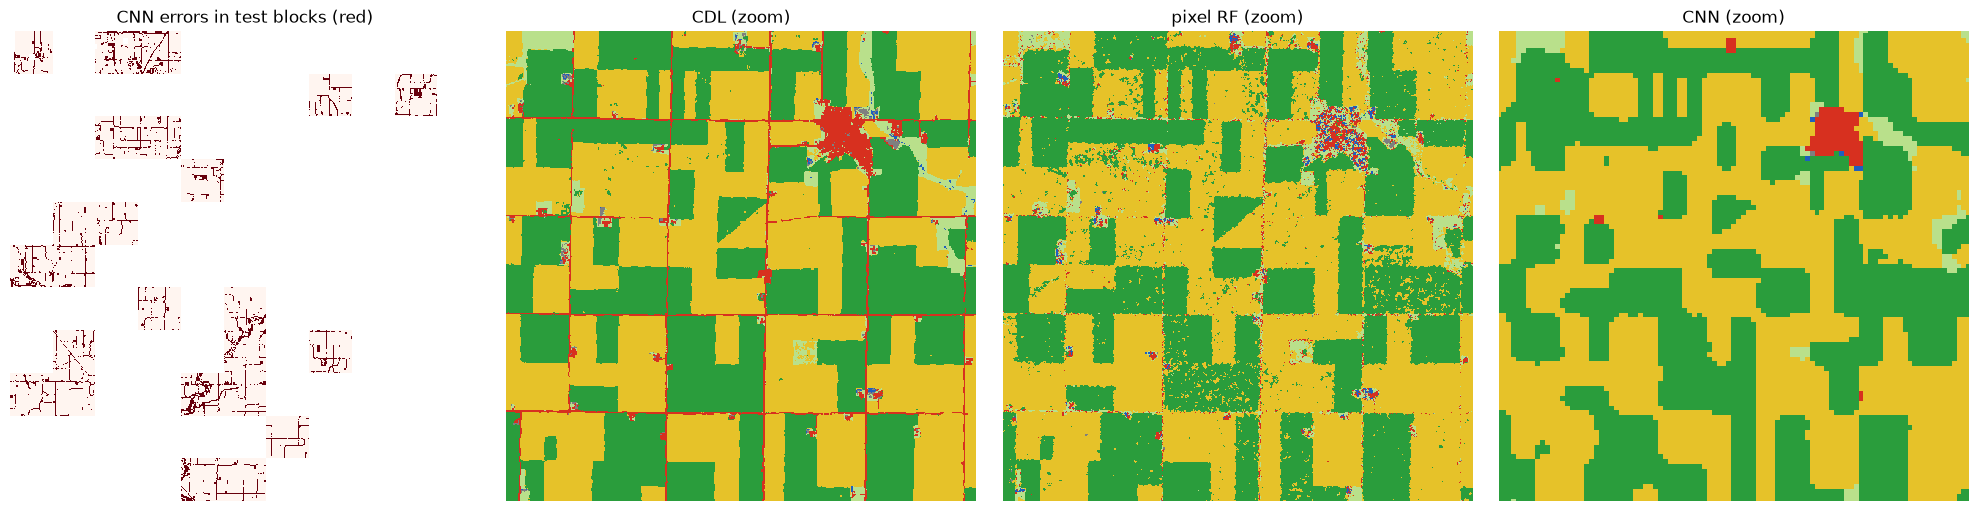

CNN       error rate within 3 px of a CDL boundary: 0.385 | in field interiors: 0.012 | share of pixels near a boundary 0.29
pixel RF  error rate within 3 px of a CDL boundary: 0.308 | in field interiors: 0.031 | share of pixels near a boundary 0.29


In [29]:
err = np.where(m, (pred != ref_l).astype(float), np.nan)  # 1 = wrong, 0 = right, NaN = not tested
zoom = (slice(256 * 2, 256 * 5), slice(256 * 2, 256 * 5))  # a 3 x 3-block zoom
fig, ax = plt.subplots(1, 4, figsize=(20, 5))  # four panels
# CNN errors
ax[0].imshow(err, cmap="Reds", vmin=0, vmax=1, interpolation="nearest"); ax[0].set_title("CNN errors in test blocks (red)")
# CDL zoom
ax[1].imshow(sh(ref_l)[zoom], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[1].set_title("CDL (zoom)")
# RF zoom
ax[2].imshow(sh(RF["mt"]["pred"])[zoom], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[2].set_title("pixel RF (zoom)")
# CNN zoom
ax[3].imshow(sh(pred)[zoom], cmap=cmap, vmin=-0.5, vmax=K - 0.5, interpolation="nearest"); ax[3].set_title("CNN (zoom)")
for a in ax: a.axis("off")  # no axes
plt.tight_layout(); plt.show()  # arrange and draw
edge = np.zeros_like(ref_l, bool)  # field boundaries in the CDL
# pixels whose neighbour has another class
edge[1:-1, 1:-1] = (ref_l[1:-1, 1:-1] != ref_l[:-2, 1:-1]) | (ref_l[1:-1, 1:-1] != ref_l[2:, 1:-1]) | (ref_l[1:-1, 1:-1] != ref_l[1:-1, :-2]) | (ref_l[1:-1, 1:-1] != ref_l[1:-1, 2:])
from scipy.ndimage import binary_dilation  # dilation
near = binary_dilation(edge, iterations=3)  # a 3-pixel band around the boundaries
rf_pred = RF["mt"]["pred"]  # RF map
for nm_, pr_, mm in [("CNN", pred, m), ("pixel RF", rf_pred, rf_m)]:  # both maps
    # error rate near boundaries and inside fields
    print(f"{nm_:9s} error rate within 3 px of a CDL boundary: {(pr_[mm & near] != ref_l[mm & near]).mean():.3f} | in field interiors: {(pr_[mm & ~near] != ref_l[mm & ~near]).mean():.3f}"
          f" | share of pixels near a boundary {(mm & near).sum() / mm.sum():.2f}")

## Summary of the experiments


In [30]:
best_arch = arch_res["test acc"].idxmax()  # the best architecture
print("Architectures (1 seed, plain CE, multi-temporal Lee input):")  # header
# architectures sorted by test accuracy
print(arch_res[["parameters", "sec/epoch", "best val acc", "test acc", "macro F1"]].sort_values("test acc", ascending=False).to_string())
print("\nSAR input ablations on ResNet-18 (mean ± SD over", len(SEEDS), "seeds):")  # header
print(tab_in[["test_acc", "test_sd", "macro_f1", "macro_f1_sd"]].to_string())  # the input ablations
print("\nTraining ablations on ResNet-18:")  # header
print(tab[["test_acc", "test_sd", "macro_f1", "macro_f1_sd"]].to_string())  # the training ablations
# the pixel random forest
print(f"\nPixel Random Forest (test blocks, pixel level): OA {RF['mt']['rep']['overall_accuracy']:.4f}, macro-F1 {RF['mt']['rep']['macro_f1']:.4f}"
      f" | unfiltered input OA {RF['raw']['rep']['overall_accuracy']:.4f}")
# the final model
print(f"Final ResNet-18 ({best_cfg}): chip OA {rep['overall_accuracy']:.4f} (TTA), macro-F1 {rep['macro_f1']:.4f}; map pixel OA on test blocks {oa_px:.4f}")

Architectures (1 seed, plain CE, multi-temporal Lee input):
                 parameters  sec/epoch  best val acc  test acc  macro F1
arch                                                                    
simple_cnn            17958     0.7690        0.9975    0.9961    0.9975
efficientnet_b0     4017250     2.8402        0.9951    0.9941    0.9911
resnet18           11201542     1.3357        0.9955    0.9939    0.9851
vgg_small            290246     0.8857        0.9969    0.9939    0.9928
resnet34           21309702     1.9838        0.9944    0.9927    0.9839
lenet                 62716     0.9690        0.9894    0.9925    0.9682
convnext_tiny      27835494     2.8824        0.9899    0.9884    0.9529
vit_b_16           87032070     5.6119        0.9899    0.9884    0.9695
swin_t             27534720     5.8331        0.9874    0.9868    0.9802

SAR input ablations on ResNet-18 (mean ± SD over 3 seeds):
                              test_acc  test_sd  macro_f1  macro_f1_sd
config

## Interpretation, caveats and recommended recipe

**What the numbers say (one AOI, one year, one spatial split).**

* **Chip-level accuracy is very high (about 99.5 %) but is an optimistic number.** The test blocks contain 2,540 corn and 1,828 soybean chips, only 31 grass chips, one wetland chip and *no* developed or "other" chips, so the accuracy is essentially a corn-versus-soybean score on chips that are at least 60 % one class. The per-class F1 of the rare classes in this table is not estimable. Do not read it as a six-class accuracy.
* **The pixel-level test is the more honest one.** Evaluated on every test-block pixel against the CDL, the ResNet-18 map reaches OA $\approx 0.88$ (kappa $\approx 0.78$, macro-F1 $\approx 0.46$), and the *pixel* Random Forest on the same blocks reaches OA $\approx 0.89$ (kappa $\approx 0.81$, macro-F1 $\approx 0.54$). In this experiment the CNN therefore **did not beat the per-pixel RF** at pixel level. The CNN is better inside fields (error rate about 1 % versus 3 % more than 3 px from a boundary) but worse within 3 px of a CDL boundary (about 39 % versus 31 %), because the chip-level model assigns *one label per 32 px chip* and predicts blocky, smoothed field edges, and because rare, small classes (developed, wetland, other) are almost never the majority of a chip. A segmentation network (notebook 09_09_04_01) is the right tool when boundaries matter.
* **Architectures are indistinguishable at chip level.** Eight of the nine reach 98.7-99.6 % test accuracy with one seed; differences of a few tenths of a percent are within the seed-to-seed SD seen in the ablations (up to about 0.3 %). The smallest model (`simple_cnn`, 18 k parameters) is as good as ResNet-18 and about 5-8 times cheaper than the transformers, which have the lowest scores here. This is a small-image, two-dominant-class task; it says little about which architecture is better in general.
* **Season length matters far more than the architecture or filter.** Using only the 21 May scene, accuracy is about 0.73; adding 13 July gives 0.79; adding 18 August gives 0.97, and adding 11 September gives 0.99. Corn and soybeans differ most in August-September (d' about 1.4-2.3) and again in October (after harvest), and hardly at all in May and July (|d'| < 0.5). Removing 11 September is the most costly single-date removal (0.979 vs 0.992). The practical consequence is that in-season mapping before mid-August is not supported by this data set.
* **Polarisation.** VH alone matches VV+VH (0.993 vs 0.992) while VV alone is worse (0.986, with a much lower macro-F1); VH is the more crop-sensitive channel. The SD of macro-F1 is large (up to 0.05-0.08) because of the tiny rare-class counts.
* **Speckle filtering.** Filtering increased the equivalent number of looks from about 6-7 to 15-33 on pure fields (multi-temporal filter: 15-18) but gave **no measurable gain in chip-level accuracy** (raw 0.993, single-date Lee 0.994, multi-temporal Lee 0.992, all within about 2 SD). A CNN can learn its own averaging over a 32 px chip. For the *pixel* RF, in contrast, filtering was decisive (OA 0.835 raw to 0.889 filtered).
* **Training ingredients.** Dihedral augmentation and CutMix improved the mean test accuracy by about 0.3 percentage points and macro-F1 by up to 1.6 points, more than the seed SD of about 0.1 points for accuracy, so they are worth keeping. Class weighting and focal loss did not help in accuracy, and weighted CE was less stable in macro-F1 (SD 0.07).

**Caveats.**

1. **The label is the CDL, itself a model product** (a decision-tree classifier fed with optical and other imagery), at roughly 85-95 % accuracy for corn and soybeans and much lower for minor classes. The CNN is partly learning to reproduce another classifier, and agreement with the CDL is not field-verified accuracy.
2. **Same-scene spatial split.** Blocks of 256 px (2.56 km) are separated, but all blocks come from one 30 × 30 km AOI and one year. Transfer to other regions or years was not tested; backscatter depends on weather, soil moisture and planting dates.
3. **Five dates, one missing month.** There is no June acquisition for 2024 and the May scene is from relative orbit 165 whereas the others are from orbit 63 (different incidence angle), so the May channels are not strictly comparable with the rest.
4. **Rare classes** (developed, wetland, other) have 0-1 chips in the test blocks, and their train/val counts are 20-250. Their metrics are not reliable.
5. **Single seed for the architecture benchmark**; the ablations use three seeds and show mean ± SD, but three seeds give only a rough SD.

**Recommended recipe for this task.** Use VH (or VV+VH) backscatter in dB from at least the August and September dates, filter with the multi-temporal Lee filter if you feed a per-pixel model, a small CNN or ResNet-18 with dihedral augmentation and CutMix for chip-level corn/soybean mapping, and move to a segmentation network when field boundaries and minor classes matter.
